#  Credit Risk Prediction and Expected Loss

## 1. Introduction

### 1.1 Problem Statement


Credit risk is the possibility that a borrower will fail to meet their repayment obligations, resulting in financial losses for lenders. Accurately assessing credit risk is essential for financial institutions to minimize losses, improve lending decisions, and maintain financial stability.

### 1.2 Project Objectives

This project aims to develop a machine learning-based credit risk assessment framework. The main objectives are to:


1.   Explore and analyze factors associated with credit card payment defaults.
2. Evaluate model performance using appropriate classification and probability calibration metrics.
3. Identify key risk factors using model interpretability techniques.
4. Estimate Expected Loss (EL) using predicted default probabilities and assumed Loss Given Default (LGD) and Exposure at Default (EAD).
5. Analyze potential financial losses under different risk scenarios.





### 1.3 Dataset Description

The project uses the Default of Credit Card Clients dataset from the UCI Machine Learning Repository.

The dataset contains information on 30,000 credit card clients in Taiwan, including 23 predictor variables covering demographic characteristics, credit limits, repayment history, bill statements, and previous payments.

The target variable, default.payment.next.month, indicates whether a client defaulted on their payment in the following month (1 = default, 0 = no default).

The dataset provides historical records from April to September 2005, with the default outcome recorded for October 2005.

## 2. Import libraries and data

In [2]:
%pip install lightgbm catboost -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style="whitegrid")
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu
from scipy.stats import spearmanr
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn import set_config
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    brier_score_loss,
    log_loss
)

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import (
    CalibratedClassifierCV,
    CalibrationDisplay
)


In [4]:
df=pd.read_excel("default of credit card clients.xls")

## 3. Exploratory Data Analysis (EDA)

### 3.1 Shape, data types, null values and duplicates

In [5]:
print(df.shape)

(30001, 25)


Dataset contains 30001 rows and 25 columns.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30001 entries, 0 to 30000
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  30001 non-null  object
 1   X1          30001 non-null  object
 2   X2          30001 non-null  object
 3   X3          30001 non-null  object
 4   X4          30001 non-null  object
 5   X5          30001 non-null  object
 6   X6          30001 non-null  object
 7   X7          30001 non-null  object
 8   X8          30001 non-null  object
 9   X9          30001 non-null  object
 10  X10         30001 non-null  object
 11  X11         30001 non-null  object
 12  X12         30001 non-null  object
 13  X13         30001 non-null  object
 14  X14         30001 non-null  object
 15  X15         30001 non-null  object
 16  X16         30001 non-null  object
 17  X17         30001 non-null  object
 18  X18         30001 non-null  object
 19  X19         30001 non-null  object
 20  X20   

All columns are classified as object.

In [7]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100,
})
df.rename(columns={'Unnamed: 0': 'ID'}, inplace=True)

In [8]:
display(missing_values)

,Missing Count,Missing Percentage
Unnamed: 0,0,0.00
X1,0,0.00
X2,0,0.00
X3,0,0.00
X4,0,0.00
X5,0,0.00
X6,0,0.00
X7,0,0.00
X8,0,0.00
X9,0,0.00


There is no missing values.

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
if "ID" in df.columns:
    print("Duplicate client IDs:", df["ID"].duplicated().sum())

Duplicate client IDs: 0


There are no duplicate values.

In [11]:
data_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Non-Null Count": df.notnull().sum(),
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

In [12]:
display(data_summary)

,Data Type,Non-Null Count,Missing Values,Missing (%),Unique Values
ID,object,30001,0,0.00,30001
X1,object,30001,0,0.00,82
X2,object,30001,0,0.00,3
X3,object,30001,0,0.00,8
X4,object,30001,0,0.00,5
X5,object,30001,0,0.00,57
X6,object,30001,0,0.00,12
X7,object,30001,0,0.00,12
X8,object,30001,0,0.00,12
X9,object,30001,0,0.00,12


### 3.2 Cleaning the data

In [13]:
display(df.head(5))

,ID,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


In [14]:
print(df["Y"].value_counts())

Y
0                             23364
1                              6636
default payment next month        1
Name: count, dtype: int64



The initial data inspection revealed 30,001 observations instead of the expected 30,000, with all variables incorrectly classified as object data types. Although no missing values were detected, the target variable contained three unique values instead of the expected two.

Further examination revealed that an additional header row had been incorrectly interpreted as a data record. This caused the incorrect data types and inflated the number of unique values in several columns.

To address these issues, the redundant header row must be removed, the correct column names assigned, and all variables converted to appropriate numerical data types.

In [15]:
df.columns = df.iloc[0]
df = df.iloc[1:].copy()
df.reset_index(drop=True, inplace=True)
df = df.apply(pd.to_numeric, errors="raise")


In [16]:
display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [17]:
df.rename(columns={"default payment next month": "DEFAULT"}, inplace=True)

In [18]:
display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [19]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_0      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   3

None

After cleaning, the dataset contains 30,000 observations and 25 columns, all stored as int64, with no missing values.

### 3.3 Target Variable Distribution

In [20]:
target_counts = df["DEFAULT"].value_counts().sort_index()

In [21]:
target_percentages = df["DEFAULT"].value_counts(normalize=True).sort_index() * 100

In [22]:
target_summary = pd.DataFrame({"Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

In [23]:
target_summary.index = ["No Default (0)", "Default (1)"]

In [24]:
display(target_summary)

,Count,Percentage (%)
No Default (0),23364,77.88
Default (1),6636,22.12


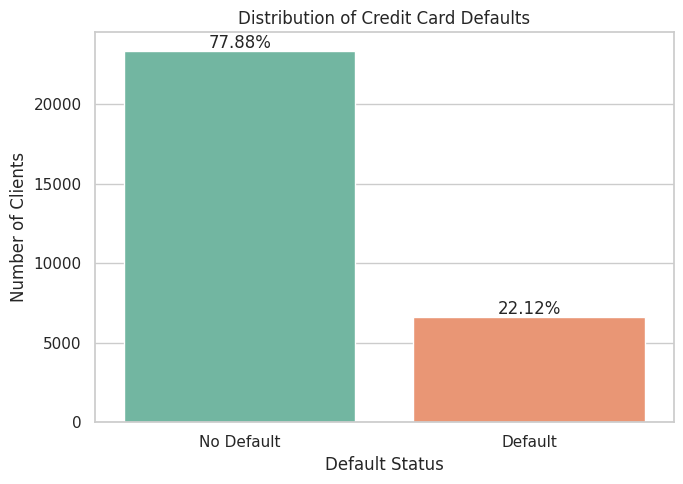

In [25]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(
    data=df,
    x="DEFAULT",
    hue="DEFAULT",
    palette="Set2",
    legend=False
)
plt.title("Distribution of Credit Card Defaults")
plt.xlabel("Default Status")
plt.ylabel("Number of Clients")
plt.xticks([0, 1], ["No Default", "Default"])
for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 200,
        f"{target_percentages.iloc[i]:.2f}%",
        ha="center"
    )
plt.tight_layout()
plt.show()


The target variable is moderately imbalanced, with approximately 77.88% of clients classified as non-default and 22.12% as default. This imbalance indicates that accuracy alone may be misleading when evaluating classification models. Therefore, additional metrics such as Precision, Recall, F1-score, ROC-AUC, and PR-AUC will be considered.

### 3.4 Credit Limit Distribution

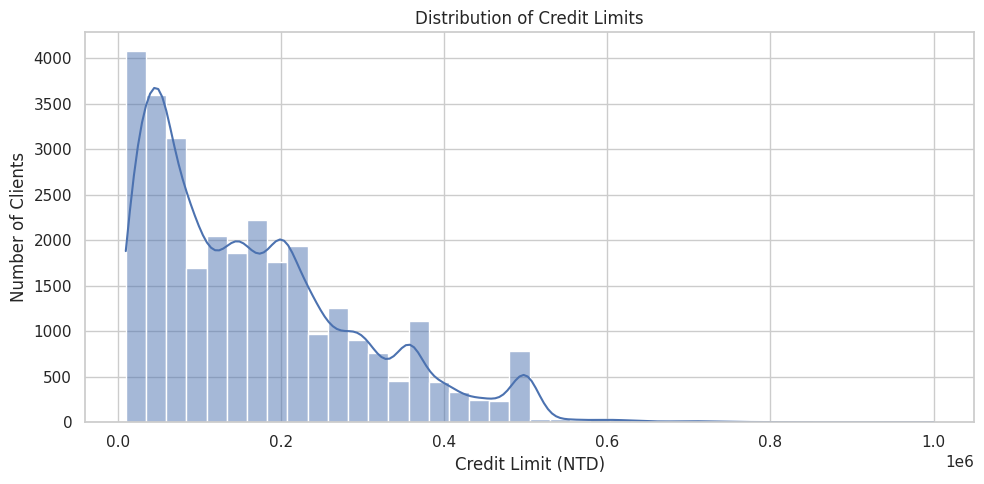

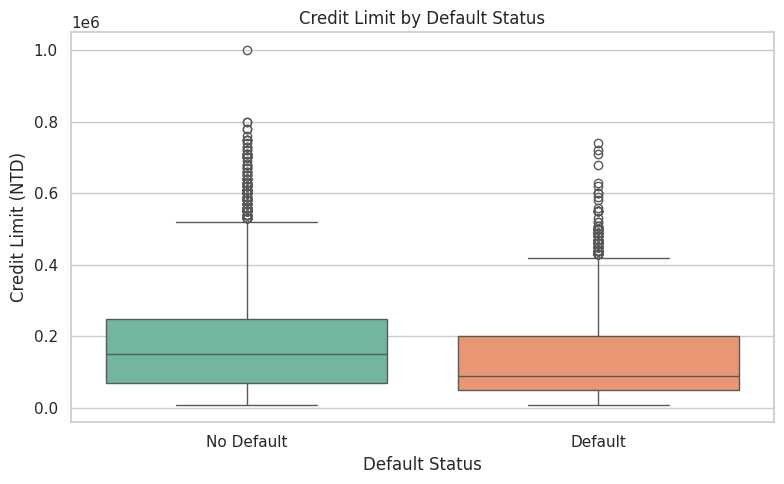

In [26]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)
plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit (NTD)")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="DEFAULT",
    y="LIMIT_BAL",
    hue="DEFAULT",
    palette="Set2",
    legend=False
)
plt.title("Credit Limit by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Credit Limit (NTD)")
plt.xticks([0, 1], ["No Default", "Default"])
plt.tight_layout()
plt.show()

The distribution of credit limits is right-skewed, with most clients having credit limits below 200,000 NTD and relatively few exceeding 500,000 NTD. The boxplot shows that non-defaulting clients generally have higher credit limits, with a median of approximately 150,000 NTD compared to 90,000 NTD among defaulting clients. Both groups contain high-value outliers, although non-defaulting clients exhibit greater variability and higher maximum credit limits. Overall, these findings suggest an association between lower credit limits and credit default, indicating that LIMIT_BAL may be a useful predictor in machine learning models.

### 3.5 Age Distribution


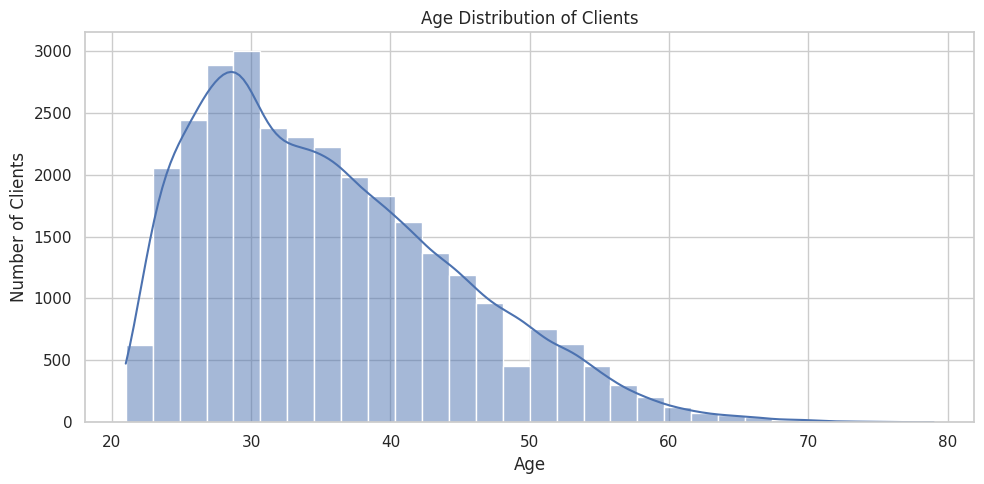

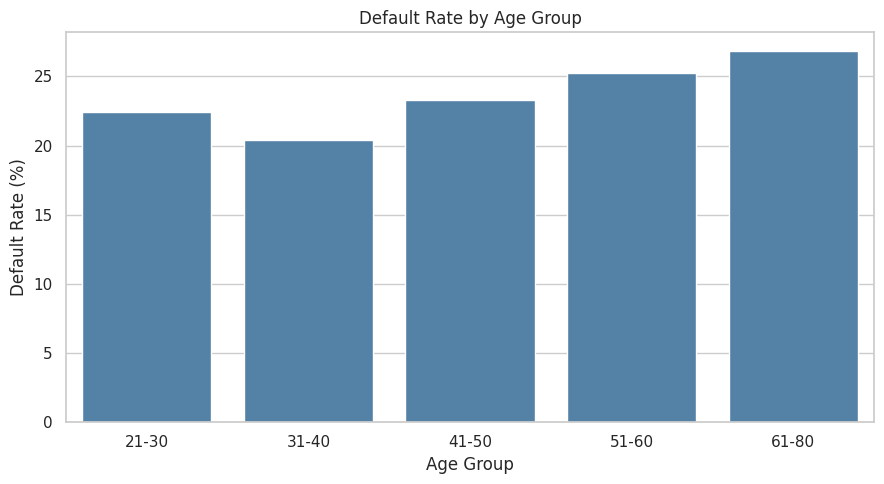

In [27]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True
)
plt.title("Age Distribution of Clients")
plt.xlabel("Age")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()
df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 80],
    labels=["21-30", "31-40", "41-50", "51-60", "61-80"]
)
age_default = df.groupby(
    "AGE_GROUP", observed=True
)["DEFAULT"].mean() * 100

plt.figure(figsize=(9, 5))
sns.barplot(
    x=age_default.index,
    y=age_default.values,
    color="steelblue"
)
plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

The age distribution is positively skewed, with most clients aged between 25 and 40 years. Default rates vary across age groups, with the lowest rate observed among clients aged 31–40 (approximately 20.4%) and the highest among those aged 61–80 (approximately 26.7%). Default rates generally increase after age 40, suggesting a possible association between age and credit risk. However, the smaller number of older clients should be considered when interpreting these differences.

### 3.6 Bill Statement Amounts

,count,mean,std,min,25%,50%,75%,max
0,,,,,,,,
BILL_AMT1,30000.00,51223.33,73635.86,-165580.00,3558.75,22381.50,67091.00,964511.00
BILL_AMT2,30000.00,49179.08,71173.77,-69777.00,2984.75,21200.00,64006.25,983931.00
BILL_AMT3,30000.00,47013.15,69349.39,-157264.00,2666.25,20088.50,60164.75,1664089.00
BILL_AMT4,30000.00,43262.95,64332.86,-170000.00,2326.75,19052.00,54506.00,891586.00
BILL_AMT5,30000.00,40311.40,60797.16,-81334.00,1763.00,18104.50,50190.50,927171.00
BILL_AMT6,30000.00,38871.76,59554.11,-339603.00,1256.00,17071.00,49198.25,961664.00


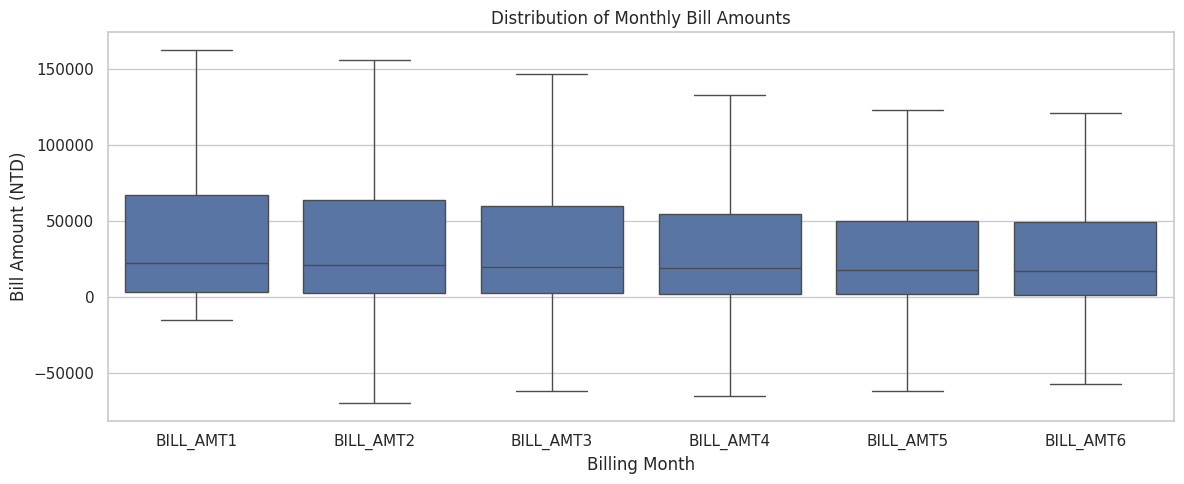

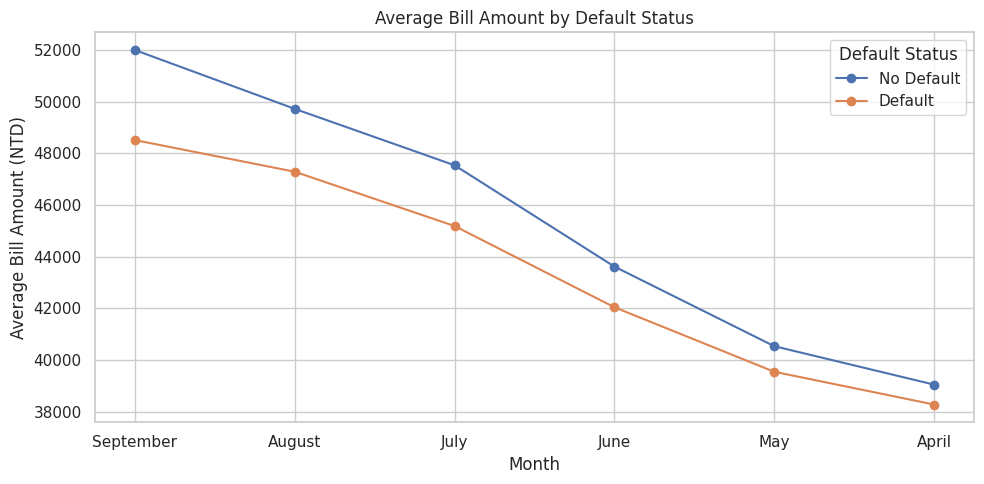

In [28]:
bill_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3","BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
display(df[bill_cols].describe().T)
bill_long = df[bill_cols].melt(
    var_name="Month",
    value_name="Bill Amount"
)
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=bill_long,
    x="Month",
    y="Bill Amount",
    showfliers=False
)
plt.title("Distribution of Monthly Bill Amounts")
plt.xlabel("Billing Month")
plt.ylabel("Bill Amount (NTD)")
plt.tight_layout()
plt.show()
bill_means = df.groupby("DEFAULT")[bill_cols].mean().T
bill_means.index = ["September", "August", "July","June", "May", "April"]
bill_means.columns = ["No Default", "Default"]
bill_means.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)
plt.title("Average Bill Amount by Default Status")
plt.xlabel("Month")
plt.ylabel("Average Bill Amount (NTD)")
plt.legend(title="Default Status")
plt.tight_layout()
plt.show()

The monthly bill amounts exhibit substantial variability and right-skewed distributions, with some negative balances and potentially extreme values. Average bill amounts are consistently higher among non-defaulting clients, and both groups show increasing balances from April to September 2005. These findings suggest that absolute bill amounts alone may not be sufficient indicators of default risk. Additional features, such as credit utilization ratios and repayment behavior, may provide more meaningful insights into clients' financial risk.

### 3.8 Credit Utilization

In [29]:
bill_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3","BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
for i in range(1, 7):
    df[f"UTILIZATION_{i}"] = (df[f"BILL_AMT{i}"] / df["LIMIT_BAL"])
util_cols = [f"UTILIZATION_{i}" for i in range(1, 7)]
df["AVG_UTILIZATION"] = df[util_cols].mean(axis=1)
display(df[util_cols + ["AVG_UTILIZATION"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
0,,,,,,,,
UTILIZATION_1,30000.00,0.42,0.41,-0.62,0.02,0.31,0.83,6.46
UTILIZATION_2,30000.00,0.41,0.40,-1.40,0.02,0.30,0.81,6.38
UTILIZATION_3,30000.00,0.39,0.40,-1.03,0.02,0.27,0.76,10.69
UTILIZATION_4,30000.00,0.36,0.37,-1.37,0.01,0.24,0.67,5.15
UTILIZATION_5,30000.00,0.33,0.35,-0.88,0.01,0.21,0.60,4.94
UTILIZATION_6,30000.00,0.32,0.35,-1.51,0.01,0.19,0.58,3.89
AVG_UTILIZATION,30000.00,0.37,0.35,-0.23,0.03,0.28,0.69,5.36


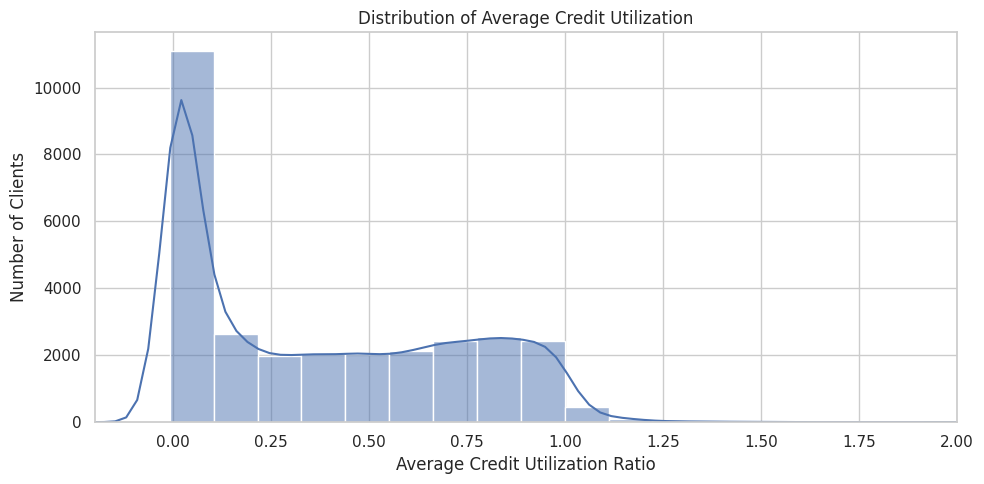

In [30]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="AVG_UTILIZATION",
    bins=50,
    kde=True
)
plt.xlim(-0.2, 2)
plt.title("Distribution of Average Credit Utilization")
plt.xlabel("Average Credit Utilization Ratio")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

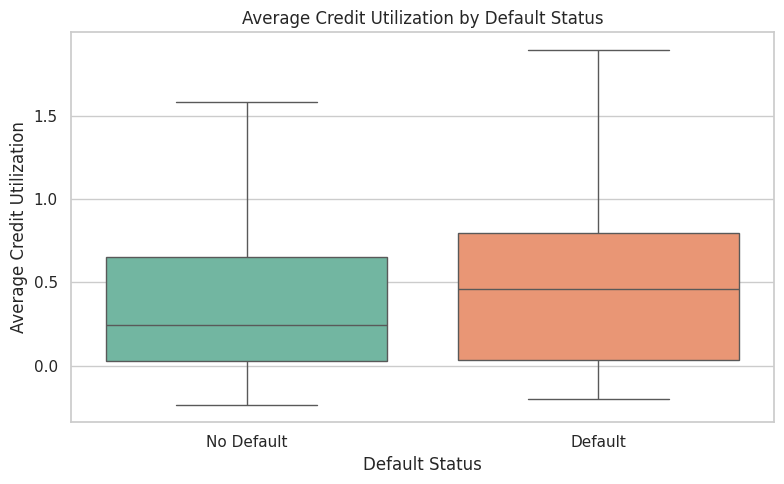

,count,mean,std,min,25%,50%,75%,max
DEFAULT,,,,,,,,
0,23364.00,0.35,0.34,-0.23,0.03,0.24,0.65,5.36
1,6636.00,0.45,0.37,-0.20,0.04,0.46,0.79,2.64


In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="DEFAULT",
    y="AVG_UTILIZATION",
    hue="DEFAULT",
    palette="Set2",
    legend=False,
    showfliers=False
)
plt.title("Average Credit Utilization by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Average Credit Utilization")
plt.xticks([0, 1], ["No Default", "Default"])
plt.tight_layout()
plt.show()
display(df.groupby("DEFAULT")["AVG_UTILIZATION"].describe())

,Clients,Defaults,Default_Rate
UTILIZATION_GROUP,,,
≤ 0%,1071,368,34.36
0-30%,14196,2363,16.65
30-50%,3674,759,20.66
50-70%,3827,971,25.37
70-100%,6595,1957,29.67
> 100%,637,218,34.22


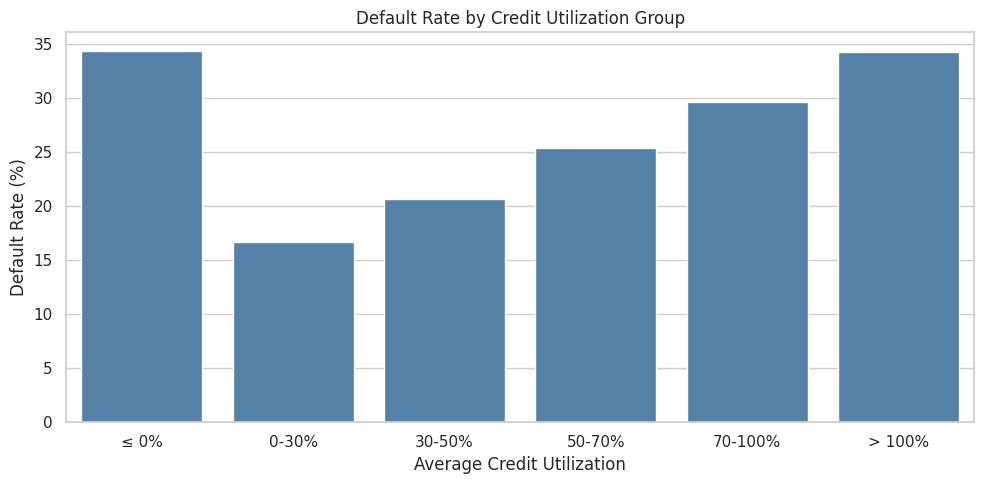

In [32]:

bins = [-float("inf"), 0, 0.3, 0.5, 0.7, 1, float("inf")]
labels = ["≤ 0%","0-30%","30-50%","50-70%","70-100%","> 100%"]
df["UTILIZATION_GROUP"] = pd.cut(df["AVG_UTILIZATION"],bins=bins,labels=labels)
util_summary = (df.groupby("UTILIZATION_GROUP", observed=True).agg(
        Clients=("DEFAULT", "count"),
        Defaults=("DEFAULT", "sum"),
        Default_Rate=("DEFAULT", "mean")
    )
)
util_summary["Default_Rate"] *= 100
display(util_summary.round(2))
plt.figure(figsize=(10, 5))
sns.barplot(
    x=util_summary.index,
    y=util_summary["Default_Rate"],
    color="steelblue"
)
plt.title("Default Rate by Credit Utilization Group")
plt.xlabel("Average Credit Utilization")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [33]:
print("Clients with negative utilization:",(df["AVG_UTILIZATION"] < 0).sum())
print("Clients with utilization above 100%:",(df["AVG_UTILIZATION"] > 1).sum())
print("Clients with utilization between 0% and 100%:",df["AVG_UTILIZATION"].between(0, 1).sum())

Clients with negative utilization: 201
Clients with utilization above 100%: 637
Clients with utilization between 0% and 100%: 29162


The analysis reveals an association between credit utilization and default risk. Defaulting clients exhibit higher median utilization (approximately 45%) compared to non-defaulting clients (25%). Default rates increase from approximately 16.5% among clients utilizing 0–30% of their credit limit to 34% among those exceeding 100%.

Interestingly, clients with zero or negative utilization also exhibit a relatively high default rate (34%), suggesting a nonlinear relationship. Furthermore, 201 clients have negative average utilization, while 637 exceed 100%, indicating values that warrant additional investigation.

Overall, credit utilization appears to be a potentially valuable predictive feature, although its relationship with default risk may require nonlinear modeling.

### 3.9 Repayment History

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


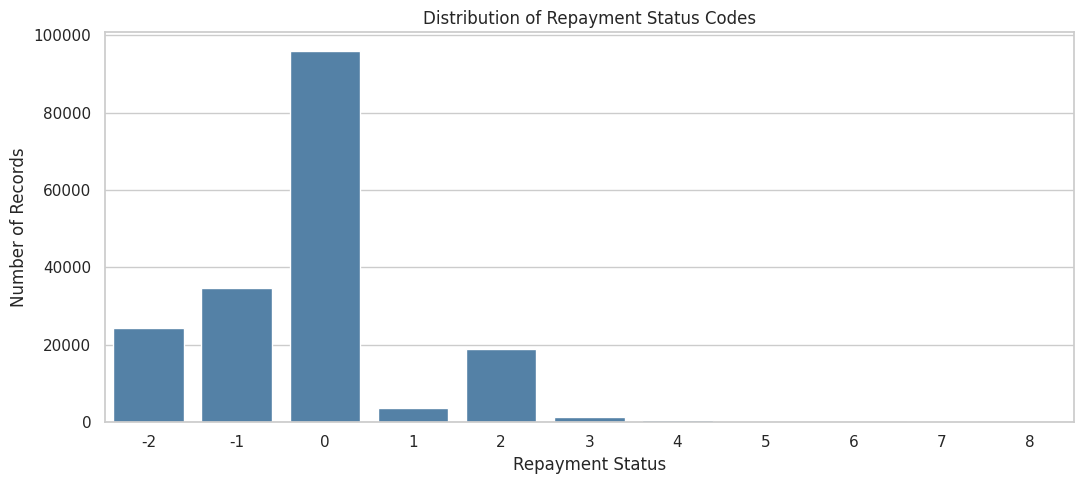

In [34]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3","PAY_4", "PAY_5", "PAY_6"]
pay_counts = df[pay_cols].apply(
    lambda col: col.value_counts()
).fillna(0).astype(int).sort_index()
display(pay_counts)
pay_long = df[pay_cols].melt(
    var_name="Month",
    value_name="Repayment Status"
)
plt.figure(figsize=(11, 5))
sns.countplot(
    data=pay_long,
    x="Repayment Status",
    color="steelblue",
    order=sorted(pay_long["Repayment Status"].unique())
)
plt.title("Distribution of Repayment Status Codes")
plt.xlabel("Repayment Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The repayment status distribution is highly concentrated around codes -2, -1, and 0, with 0 being the most frequent. Among positive delay codes, status 2 occurs most frequently, while longer repayment delays (3–8 months) are relatively rare. This suggests that severe repayment delays are uncommon in the dataset. However, the presence of undocumented repayment codes (-2 and 0) requires further investigation before preprocessing and modeling.

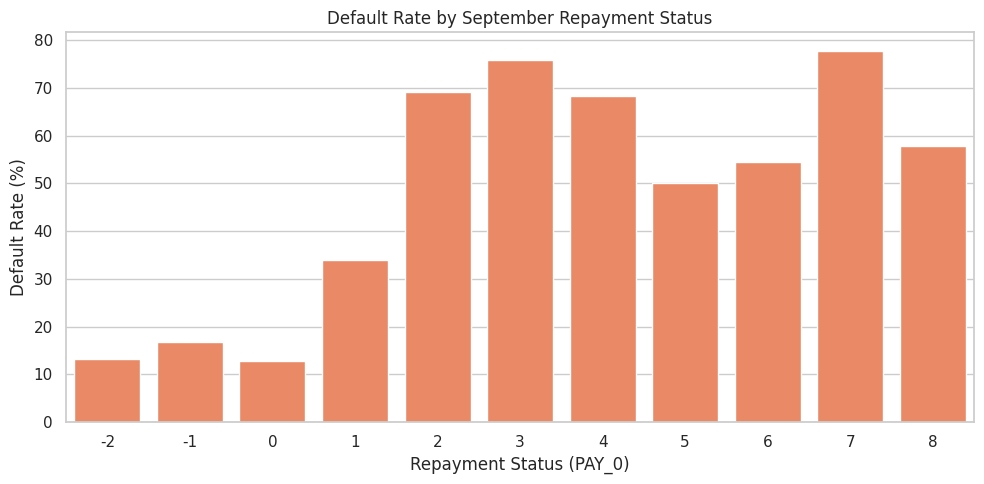

,Default Rate (%)
PAY_0,
-2,13.23
-1,16.78
0,12.81
1,33.95
2,69.14
3,75.78
4,68.42
5,50.00
6,54.55


In [35]:

repayment_default = (df.groupby("PAY_0")["DEFAULT"].mean() * 100)
plt.figure(figsize=(10, 5))
sns.barplot(
    x=repayment_default.index,
    y=repayment_default.values,
    color="coral"
)
plt.title("Default Rate by September Repayment Status")
plt.xlabel("Repayment Status (PAY_0)")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()
display(repayment_default.to_frame("Default Rate (%)"))

The analysis reveals a strong relationship between September repayment status and subsequent credit default. Clients with repayment status codes -2, -1, and 0 exhibit relatively low default rates (12.81%–16.78%), while those with a one-month delay have a default rate of 33.95%. The rate increases sharply to 69.14% for clients with a two-month delay. Longer delays are generally associated with elevated default risk, although fluctuations among severe delay categories may reflect smaller sample sizes. These findings suggest that repayment history is likely to be an important predictor of credit default.

In [36]:
repayment_summary = (df.groupby("PAY_0")["DEFAULT"].agg(
        Clients="count",
        Defaults="sum",
        Default_Rate="mean"
    )
)
repayment_summary["Default_Rate"] *= 100
display(repayment_summary.round(2))

,Clients,Defaults,Default_Rate
PAY_0,,,
-2,2759,365,13.23
-1,5686,954,16.78
0,14737,1888,12.81
1,3688,1252,33.95
2,2667,1844,69.14
3,322,244,75.78
4,76,52,68.42
5,26,13,50.00
6,11,6,54.55


The analysis confirms a strong association between repayment delays and credit default. Clients with repayment status codes -2, -1, and 0 exhibit relatively low default rates (12.81%–16.78%), while those with one- and two-month delays have substantially higher rates of 33.95% and 69.14%, respectively. A three-month delay corresponds to a default rate of 75.78%. However, severe delay categories (4–8) contain relatively few observations, making their default rates less statistically reliable. Overall, repayment status appears to be an important predictor of credit default, particularly when delays reach two or more months.

### 3.10 Previous Payment Amounts

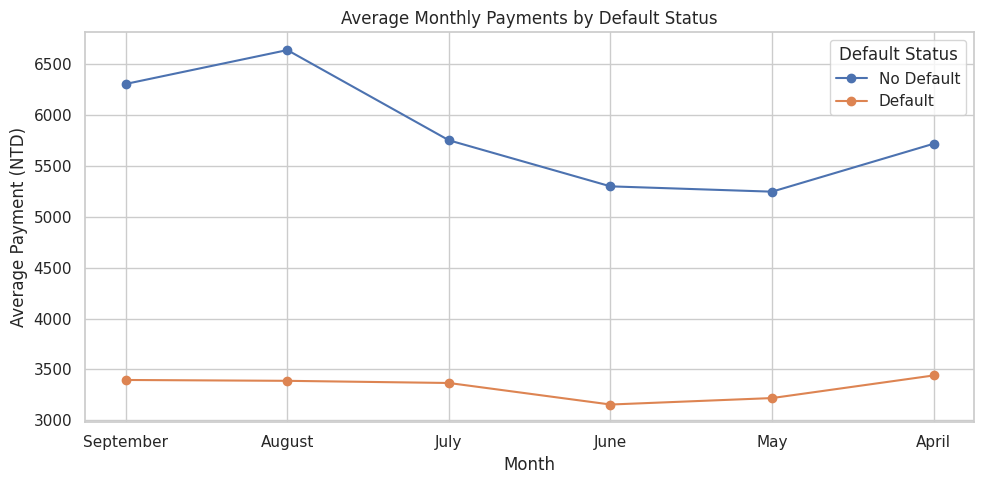

In [37]:
payment_cols = ["PAY_AMT1", "PAY_AMT2", "PAY_AMT3","PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
payment_means = df.groupby("DEFAULT")[payment_cols].mean().T
payment_means.index = ["September", "August", "July","June", "May", "April"]
payment_means.columns = ["No Default", "Default"]
payment_means.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)
plt.title("Average Monthly Payments by Default Status")
plt.xlabel("Month")
plt.ylabel("Average Payment (NTD)")
plt.legend(title="Default Status")
plt.tight_layout()
plt.show()

The analysis reveals that clients who defaulted consistently made lower average monthly payments than non-defaulting clients throughout the six-month period. Non-defaulting clients paid approximately 5,250–6,650 NTD per month, while defaulting clients averaged 3,100–3,450 NTD. These findings suggest that previous payment amounts may be useful predictors of credit default. However, payment amounts should also be considered relative to outstanding balances and credit limits to better assess repayment behavior and financial risk.

### 3.11 Categorical Variables Analysis


SEX distribution:


,count
SEX,
1,11888
2,18112


,Count,Default_Rate
SEX,,
1,11888,24.17
2,18112,20.78


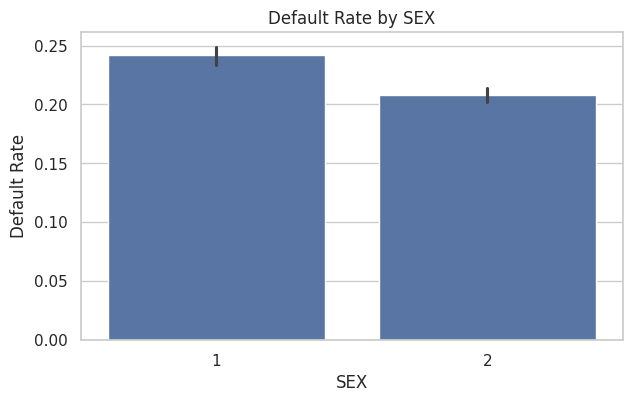


EDUCATION distribution:


,count
EDUCATION,
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51


,Count,Default_Rate
EDUCATION,,
0,14,0.00
1,10585,19.23
2,14030,23.73
3,4917,25.16
4,123,5.69
5,280,6.43
6,51,15.69


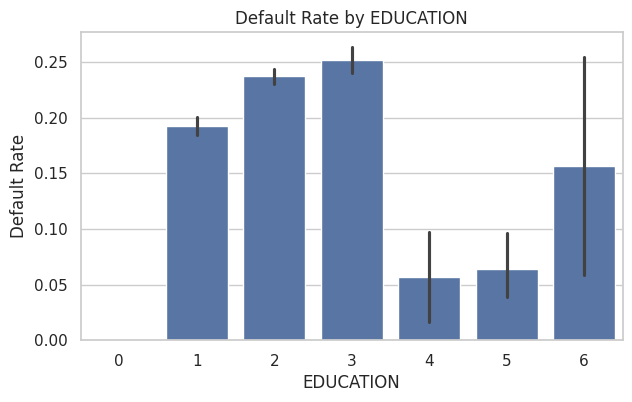


MARRIAGE distribution:


,count
MARRIAGE,
0,54
1,13659
2,15964
3,323


,Count,Default_Rate
MARRIAGE,,
0,54,9.26
1,13659,23.47
2,15964,20.93
3,323,26.01


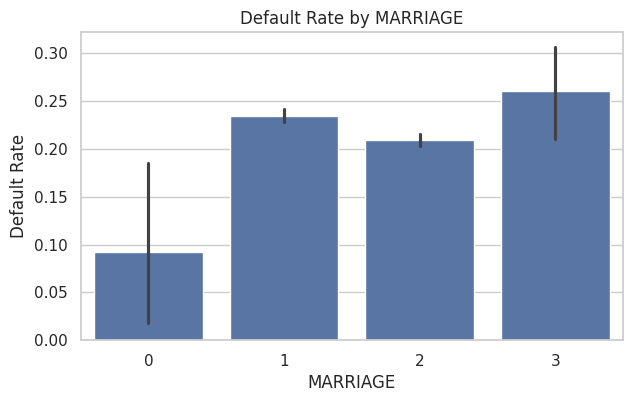

In [38]:
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]
for col in categorical_cols:
    print(f"\n{col} distribution:")
    display(df[col].value_counts().sort_index())
    summary = df.groupby(col)["DEFAULT"].agg(
        Count="count",
        Default_Rate="mean"
    )
    summary["Default_Rate"] *= 100
    display(summary.round(2))
    plt.figure(figsize=(7, 4))
    sns.barplot(
        data=df,
        x=col,
        y="DEFAULT",
        errorbar=("ci", 95)
    )
    plt.title(f"Default Rate by {col}")
    plt.ylabel("Default Rate")
    plt.show()

The dataset contains three demographic categorical variables: SEX, EDUCATION, and MARRIAGE. These variables are numerically encoded as follows:

1. SEX — Gender

    1: Male

    2: Female

2. EDUCATION — Education Level

    0: Unknown / Undocumented

    1: Graduate School

    2: University

    3: High School

    4: Others

    5: Unknown / Undocumented

    6: Unknown / Undocumented

Note: Values 0, 5, and 6 are not explicitly defined in the original dataset documentation.

3. MARRIAGE — Marital Status

    0: Unknown / Undocumented

    1: Married

    2: Single

    3: Others



The analysis reveals differences in credit default rates across demographic categories. Male clients exhibit a slightly higher default rate (approximately 24.2%) than female clients (20.8%). Regarding education, clients with a high school education have the highest default rate among the main documented categories (approximately 25.2%), followed by university graduates (23.7%) and graduate school clients (19.2%).

Marital status also shows differences, with clients classified as "Others" having the highest observed default rate (approximately 26%), followed by married (23.4%) and single clients (20.9%).

However, undocumented categories in EDUCATION and MARRIAGE, along with smaller sample sizes in certain groups, require further investigation. These findings indicate statistical associations rather than causal relationships and should be interpreted cautiously.

### 3.12 Correlation Analysis

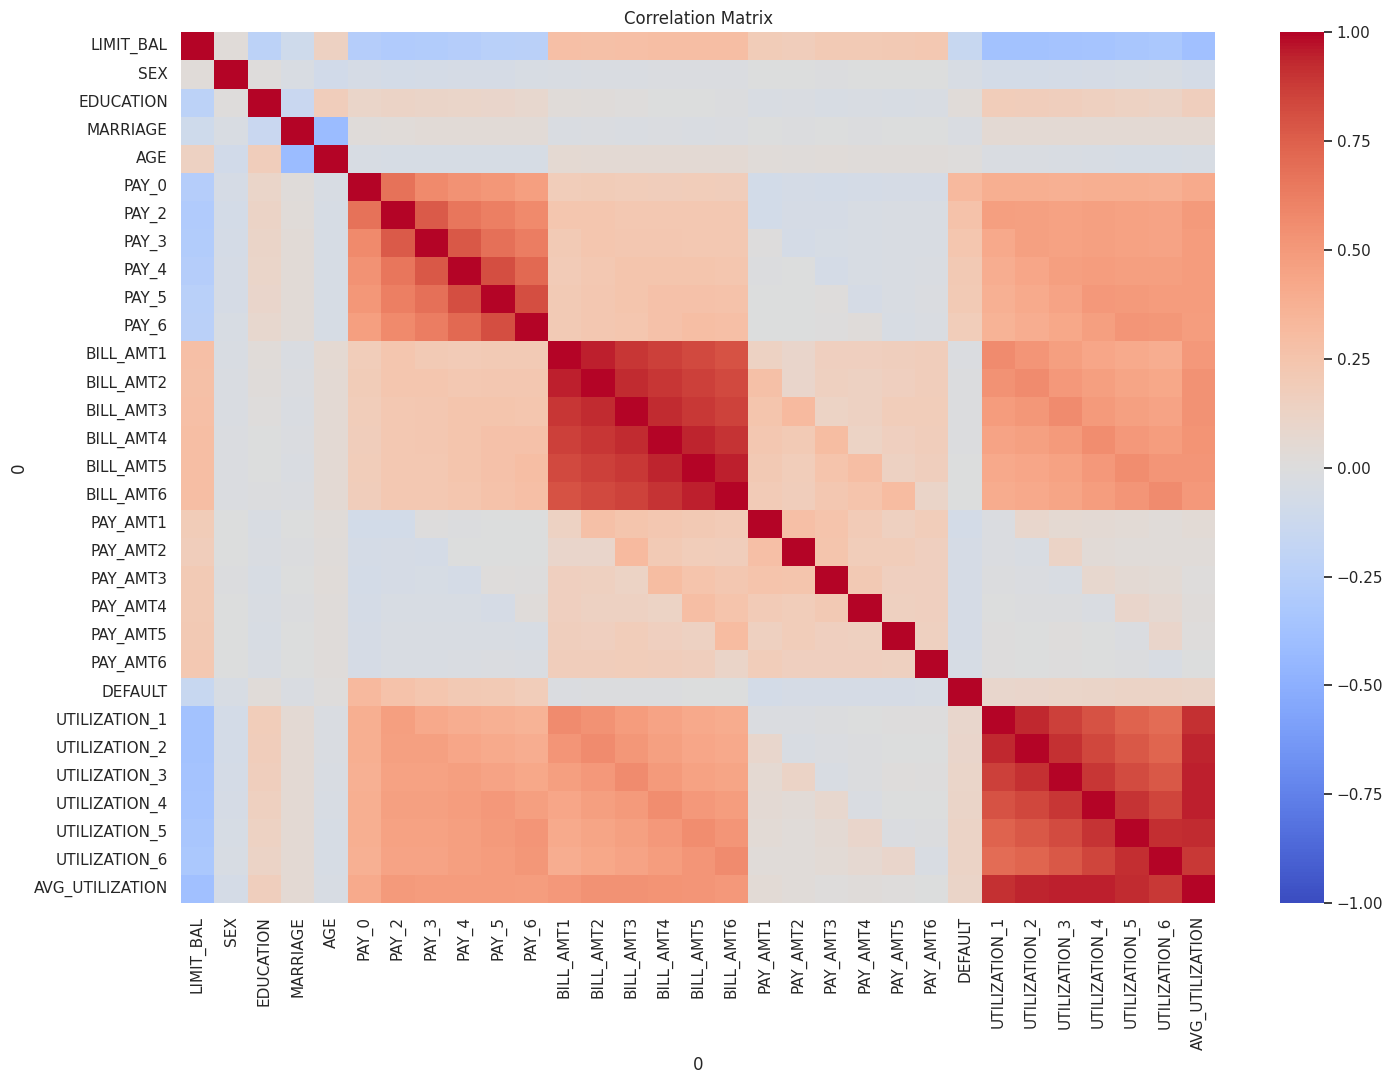

In [39]:
numeric_df = df.select_dtypes(include="number").drop(columns=["ID"], errors="ignore")
corr = numeric_df.corr()
plt.figure(figsize=(15, 11))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

The correlation matrix reveals strong positive relationships among monthly bill amounts, repayment status variables, and credit utilization ratios, indicating consistency in clients' financial and repayment behavior over time.

Repayment status, particularly recent payment delays, exhibits the strongest positive correlation with credit default, suggesting its potential importance in predicting default risk. Credit limits show a weak negative correlation with default, while bill amounts, previous payment amounts, and credit utilization demonstrate relatively weak linear relationships with the target variable.

The strong correlations among several financial variables suggest potential multicollinearity, which should be considered during model development. Additionally, weak linear correlations do not necessarily imply low predictive value, as some relationships may be nonlinear.

### 3.13 Outlier Detection

In [40]:
financial_cols = (["LIMIT_BAL"] +[f"BILL_AMT{i}" for i in range(1, 7)] +[f"PAY_AMT{i}" for i in range(1, 7)])
outlier_summary = []
for col in financial_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        "Variable": col,
        "Outlier Count": count,
        "Outlier (%)": round(count / len(df) * 100, 2)
    })
display(pd.DataFrame(outlier_summary))

,Variable,Outlier Count,Outlier (%)
0,LIMIT_BAL,167,0.56
1,BILL_AMT1,2400,8.00
2,BILL_AMT2,2395,7.98
3,BILL_AMT3,2469,8.23
4,BILL_AMT4,2622,8.74
5,BILL_AMT5,2725,9.08
6,BILL_AMT6,2693,8.98
7,PAY_AMT1,2745,9.15
8,PAY_AMT2,2714,9.05
9,PAY_AMT3,2598,8.66


The IQR method identified potential outliers in several financial variables. Credit limits contain relatively few outliers (0.56%), while monthly bill amounts exhibit approximately 8–9% and payment amounts approximately 9–10% of flagged observations.

These findings suggest substantial variability and potentially skewed distributions in clients' financial behavior. However, extreme values may represent legitimate financial transactions rather than data errors.

Therefore, outliers will not be automatically removed. Their influence on model performance will be evaluated during preprocessing and model development, with potential transformations or robust scaling considered where appropriate.

### 3.14 Payment-to-Bill Ratio

,count,mean,std,min,25%,50%,75%,max
DEFAULT,,,,,,,,
0,21409.00,2.03,86.30,0.00,0.04,0.07,0.34,11453.67
1,5993.00,0.88,14.28,0.00,0.02,0.05,0.14,1001.00


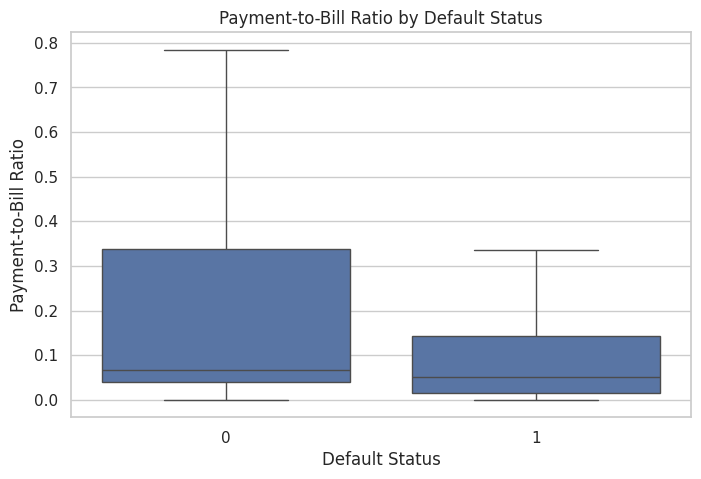

In [41]:
df["PAYMENT_BILL_RATIO"] = np.where(df["BILL_AMT1"] > 0,df["PAY_AMT1"] / df["BILL_AMT1"],np.nan)
display(df.groupby("DEFAULT")["PAYMENT_BILL_RATIO"].describe())
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="DEFAULT",
    y="PAYMENT_BILL_RATIO",
    showfliers=False
)
plt.title("Payment-to-Bill Ratio by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Payment-to-Bill Ratio")
plt.show()

The analysis indicates that non-defaulting clients generally have slightly higher payment-to-bill ratios than defaulting clients, with median values of approximately 0.06 and 0.05, respectively. Non-defaulting clients also exhibit greater variability in their payment ratios, while defaulting clients tend to have lower and more concentrated values.

These findings suggest that payment behavior relative to outstanding balances may provide useful information for predicting credit default. However, the substantial overlap between the two groups indicates that this ratio alone is unlikely to be sufficient for distinguishing defaulting from non-defaulting clients.

### 3.15 Repayment Behavior Analysis

,Count,Default_Rate
MONTHS_DELAYED,,
0,19931,11.71
1,4426,29.82
2,1899,38.76
3,1154,50.87
4,951,57.31
5,298,57.38
6,1341,70.32


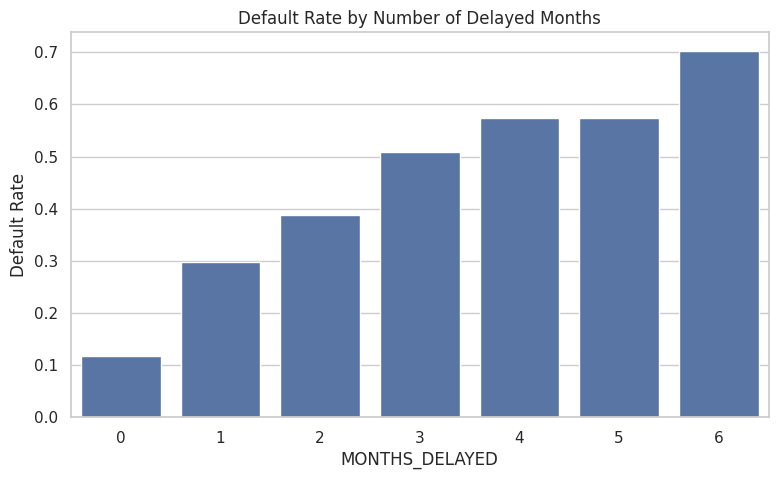

In [42]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3","PAY_4", "PAY_5", "PAY_6"]
df["MONTHS_DELAYED"] = (df[pay_cols] > 0).sum(axis=1)
df["MAX_DELAY"] = df[pay_cols].max(axis=1)
delay_summary = df.groupby("MONTHS_DELAYED")["DEFAULT"].agg(
    Count="count",
    Default_Rate="mean"
)
delay_summary["Default_Rate"] *= 100
display(delay_summary.round(2))
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="MONTHS_DELAYED",
    y="DEFAULT",
    errorbar=None
)
plt.title("Default Rate by Number of Delayed Months")
plt.ylabel("Default Rate")
plt.show()

The analysis reveals a strong positive association between the number of delayed repayment months and credit default. Clients with no recorded delays exhibit the lowest default rate (approximately 11.5%), while those with delays in all six months have the highest rate (approximately 70%).

Default rates generally increase as the frequency of late payments rises, suggesting that repeated repayment difficulties are an important indicator of credit risk.

These findings highlight MONTHS_DELAYED as a potentially valuable engineered feature for predicting credit default. However, differences in group sizes should be considered when evaluating the reliability of these results.

## 4. Statistical Analysis

The objective of the statistical analysis is to determine whether the relationships observed during EDA are statistically significant.

The analysis focuses on identifying associations between client characteristics, financial behavior, repayment history, and credit default.

For each statistical test, two hypotheses are considered:

   1. Null Hypothesis (H₀): There is no statistically significant association or difference between the variables being examined.

2. Alternative Hypothesis (H₁): A statistically significant association or difference exists between the variables.

A significance level of α = 0.05 is used. A p-value below 0.05 provides evidence against the null hypothesis, while a p-value of 0.05 or greater indicates insufficient evidence to reject it.

### 4.1 Chi-Square Test of Independence

In [43]:
categorical_cols = ["SEX","EDUCATION","MARRIAGE"]
chi_square_results = []
for col in categorical_cols:
    contingency_table = pd.crosstab(df[col],df["DEFAULT"])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    n = contingency_table.to_numpy().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan
    chi_square_results.append({
        "Variable": col,
        "Chi-Square": chi2,
        "P-value": p,
        "Degrees of Freedom": dof,
        "Cramer's V": cramers_v,
        "Min Expected Frequency": expected.min()
    })
chi_square_df = pd.DataFrame(chi_square_results)
display(chi_square_df.round(4))

,Variable,Chi-Square,P-value,Degrees of Freedom,Cramer's V,Min Expected Frequency
0,SEX,47.71,0.00,1,0.04,2629.63
1,EDUCATION,163.22,0.00,6,0.07,3.10
2,MARRIAGE,35.66,0.00,3,0.03,11.94


In [44]:
for col in categorical_cols:
    table = pd.crosstab(df[col], df["DEFAULT"])
    _, _, _, expected = chi2_contingency(table)
    print(f"\n{col}")
    print("Minimum expected:", expected.min())
    print("Cells with expected < 5:", (expected < 5).sum())
    print("Total cells:", expected.size)


SEX
Minimum expected: 2629.6256
Cells with expected < 5: 0
Total cells: 4

EDUCATION
Minimum expected: 3.0968
Cells with expected < 5: 1
Total cells: 14

MARRIAGE
Minimum expected: 11.9448
Cells with expected < 5: 0
Total cells: 8


The Chi-Square tests revealed statistically significant associations between credit default and all three categorical variables: SEX (χ² = 47.71), EDUCATION (χ² = 163.22), and MARRIAGE (χ² = 35.66), with p-values below 0.001. However, Cramer's V values (0.03–0.07) indicate very weak associations, suggesting limited practical significance. The test assumptions were generally satisfied, although EDUCATION contained one cell with an expected frequency below 5. Overall, demographic variables exhibit statistically significant but weak relationships with credit default.

### 4.2 Mann–Whitney U Test

In [45]:
numeric_cols = ["LIMIT_BAL","AGE","AVG_UTILIZATION","PAYMENT_BILL_RATIO","MONTHS_DELAYED"]

In [46]:
results=[]
for col in numeric_cols:
    group_0 = df.loc[df["DEFAULT"] == 0, col].dropna()
    group_1 = df.loc[df["DEFAULT"] == 1, col].dropna()
    stat, p = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )
    results.append({
        "Variable": col,
        "U Statistic": stat,
        "P-value": p,
        "Median No Default": group_0.median(),
        "Median Default": group_1.median()
    })


In [47]:
mw_results = pd.DataFrame(results)

In [48]:
display(mw_results.round(4))

,Variable,U Statistic,P-value,Median No Default,Median Default
0,LIMIT_BAL,95786286.50,0.00,150000.00,90000.00
1,AGE,76966879.50,0.37,34.00,34.00
2,AVG_UTILIZATION,67608506.00,0.00,0.24,0.46
3,PAYMENT_BILL_RATIO,74753821.00,0.00,0.07,0.05
4,MONTHS_DELAYED,42465114.00,0.00,0.00,1.00


The Mann–Whitney U tests identified statistically significant differences between defaulting and non-defaulting clients in credit limits, average credit utilization, payment-to-bill ratios, and the number of delayed months (all p < 0.001). Defaulting clients generally had lower credit limits (90,000 vs. 150,000 NTD), higher median credit utilization (46% vs. 24%), lower payment-to-bill ratios (0.05 vs. 0.07), and more frequent repayment delays (median 1 vs. 0 months). Age showed no statistically significant difference (p = 0.37), with both groups having a median age of 34 years. These findings reinforce the importance of financial and repayment behavior variables in credit risk assessment, although statistical significance alone does not establish predictive importance or causality.

### 4.3 Spearman Correlation Analysis

In [49]:
numeric_cols = ["LIMIT_BAL","AGE","AVG_UTILIZATION","PAYMENT_BILL_RATIO","MONTHS_DELAYED","PAY_0"]

In [50]:
spearman_results = []
for col in numeric_cols:
    subset = df[[col, "DEFAULT"]].dropna()
    rho, p_value = spearmanr(
        subset[col],
        subset["DEFAULT"]
    )
    spearman_results.append({
        "Variable": col,
        "Spearman Rho": rho,
        "P-value": p_value,
        "Significant": p_value < 0.05
    })


In [51]:
spearman_df = pd.DataFrame(spearman_results)

In [52]:
spearman_df = spearman_df.sort_values(by="Spearman Rho",key=abs,ascending=False)

In [53]:
display(spearman_df.round(4))

,Variable,Spearman Rho,P-value,Significant
4,MONTHS_DELAYED,0.39,0.00,True
5,PAY_0,0.29,0.00,True
0,LIMIT_BAL,-0.17,0.00,True
3,PAYMENT_BILL_RATIO,-0.12,0.00,True
2,AVG_UTILIZATION,0.09,0.00,True
1,AGE,0.01,0.37,False


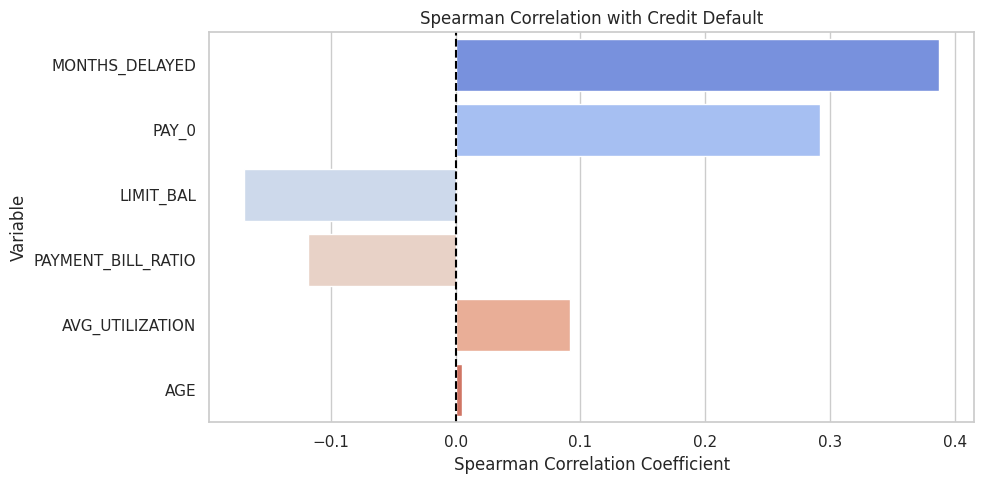

In [54]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=spearman_df,
    x="Spearman Rho",
    y="Variable",
    hue="Variable",
    palette="coolwarm",
    legend=False
)
plt.axvline(0, color="black", linestyle="--")
plt.title("Spearman Correlation with Credit Default")
plt.xlabel("Spearman Correlation Coefficient")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

Spearman correlation analysis identified MONTHS_DELAYED (ρ = 0.39) and PAY_0 (ρ = 0.29) as the variables with the strongest positive monotonic associations with credit default. Credit limits (ρ = −0.17) and payment-to-bill ratios (ρ = −0.12) showed weak negative associations, while average credit utilization exhibited a very weak positive association (ρ = 0.09). All these correlations were statistically significant (p < 0.001), whereas age showed no significant monotonic relationship (ρ = 0.01, p = 0.37). Overall, the findings suggest that repayment history is more strongly associated with default than the other examined financial and demographic characteristics.

### 4.4 Effect Size Analysis - Rank-Biserial Correlation

In [55]:
numeric_cols = ["LIMIT_BAL","AGE","AVG_UTILIZATION","PAYMENT_BILL_RATIO","MONTHS_DELAYED"]

In [56]:
effect_results = []

In [57]:
for col in numeric_cols:
    group_0 = df.loc[
        df["DEFAULT"] == 0, col
    ].dropna()

    group_1 = df.loc[
        df["DEFAULT"] == 1, col
    ].dropna()

    U, p_value = mannwhitneyu(
        group_1,
        group_0,
        alternative="two-sided"
    )

    n1 = len(group_1)
    n0 = len(group_0)

    rank_biserial = (2 * U / (n1 * n0)) - 1
    effect_results.append({
        "Variable": col,
        "Rank-Biserial": rank_biserial,
        "Absolute Effect": abs(rank_biserial),
        "P-value": p_value,
        "Median Default": group_1.median(),
        "Median No Default": group_0.median()
    })


In [58]:
effect_df = pd.DataFrame(effect_results)

In [59]:
effect_df = effect_df.sort_values(
    by="Absolute Effect",
    ascending=False
)


In [60]:
display(effect_df.round(4))

,Variable,Rank-Biserial,Absolute Effect,P-value,Median Default,Median No Default
4,MONTHS_DELAYED,0.45,0.45,0.00,1.00,0.00
0,LIMIT_BAL,-0.24,0.24,0.00,90000.00,150000.00
3,PAYMENT_BILL_RATIO,-0.17,0.17,0.00,0.05,0.07
2,AVG_UTILIZATION,0.13,0.13,0.00,0.46,0.24
1,AGE,0.01,0.01,0.37,34.00,34.00


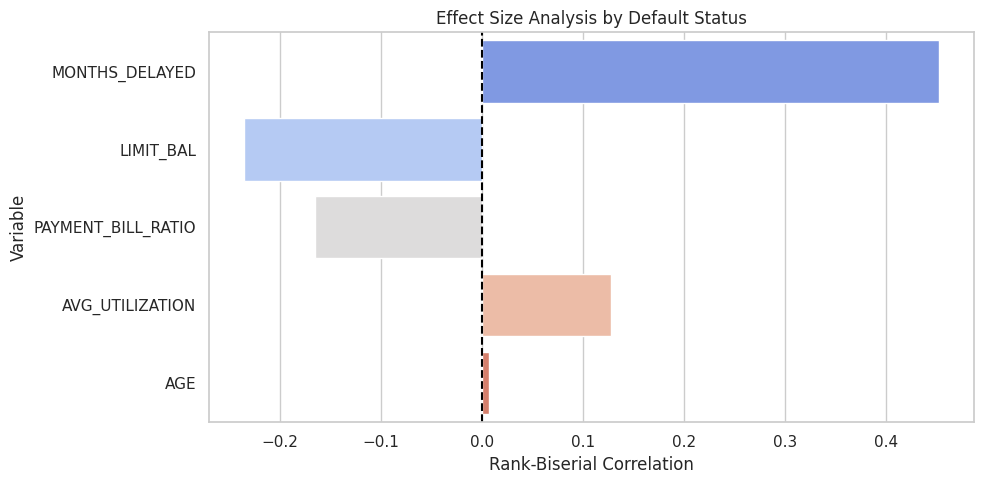

In [61]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=effect_df,
    x="Rank-Biserial",
    y="Variable",
    hue="Variable",
    palette="coolwarm",
    legend=False
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.title("Effect Size Analysis by Default Status")
plt.xlabel("Rank-Biserial Correlation")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

The rank-biserial correlation analysis identified MONTHS_DELAYED as the variable with the largest effect size (r = 0.45), indicating a moderate difference in repayment delays between defaulting and non-defaulting clients. Credit limits (r = −0.24), payment-to-bill ratios (r = −0.17), and average credit utilization (r = 0.13) exhibited smaller effects, suggesting weaker but statistically significant differences between the groups. Age showed a negligible and statistically insignificant effect (r = 0.01, p = 0.37). Overall, these findings reinforce the importance of repayment behavior in distinguishing clients with different credit default outcomes.

### 4.5 Final Statistical Analysis Conclusion

The statistical analysis identified significant associations between credit default and several financial, repayment, and demographic variables. Repayment behavior, particularly MONTHS_DELAYED, demonstrated the strongest relationship with default, supported by both Spearman correlation (ρ = 0.39) and rank-biserial correlation (r = 0.45). Credit limits, payment-to-bill ratios, and credit utilization also showed statistically significant but smaller effects, while age exhibited no significant overall monotonic association. Although demographic variables were statistically significant, their effect sizes were very small. Overall, the results highlight repayment history as a promising predictor and provide a foundation for feature engineering and machine learning model development.

## 5. Data Preprocessing & Feature Engineering

### 5.1 Feature Selection & Data Cleaning

In [62]:
df_model = df.copy()

In [63]:
print("Dataset shape:", df_model.shape)

Dataset shape: (30000, 37)


In [64]:
display(df_model.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT,AGE_GROUP,UTILIZATION_1,UTILIZATION_2,UTILIZATION_3,UTILIZATION_4,UTILIZATION_5,UTILIZATION_6,AVG_UTILIZATION,UTILIZATION_GROUP,PAYMENT_BILL_RATIO,MONTHS_DELAYED,MAX_DELAY
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1,21-30,0.20,0.16,0.03,0.00,0.00,0.00,0.06,0-30%,0.00,2,2
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1,21-30,0.02,0.01,0.02,0.03,0.03,0.03,0.02,0-30%,0.00,2,2
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0,31-40,0.32,0.16,0.15,0.16,0.17,0.17,0.19,0-30%,0.05,0,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0,31-40,0.94,0.96,0.99,0.57,0.58,0.59,0.77,70-100%,0.04,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0,51-60,0.17,0.11,0.72,0.42,0.38,0.38,0.36,30-50%,0.23,0,0


In [65]:
original_features = [
    "LIMIT_BAL",
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

In [66]:
df_model = df_model[original_features + ["DEFAULT"]].copy()

In [67]:
print("Dataset shape:", df_model.shape)

Dataset shape: (30000, 24)


In [68]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}")
    display(df_model[col].value_counts().sort_index())


SEX


,count
SEX,
1,11888
2,18112



EDUCATION


,count
EDUCATION,
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51



MARRIAGE


,count
MARRIAGE,
0,54
1,13659
2,15964
3,323


In [69]:
df_model["EDUCATION"] = df_model["EDUCATION"].replace({
    0: 5,
    6: 5
})

# EDUCATION:
# 1 = Graduate School
# 2 = University
# 3 = High School
# 4 = Others
# 5 = Unknown (original codes 0, 5, 6)

# MARRIAGE:
# 0 = Unknown
# 1 = Married
# 2 = Single
# 3 = Others

In [70]:
pay_cols = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

In [71]:
for col in pay_cols:
    print(f"{col}: {sorted(df_model[col].unique())}")

PAY_0: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


### 5.2 Train/Test Split

In [72]:
X = df_model.drop(columns=["DEFAULT"])
y = df_model["DEFAULT"]

In [73]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (30000, 23)
Target: (30000,)


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [75]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (24000, 23)
Test set: (6000, 23)


In [76]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

Training target distribution:
DEFAULT
0   77.88
1   22.12
Name: proportion, dtype: float64


In [77]:
print("Test target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Test target distribution:
DEFAULT
0   77.88
1   22.12
Name: proportion, dtype: float64


### 5.3 Feature Engineering

In [78]:
def create_features(data):

    data = data.copy()

    pay_cols = [
        "PAY_0", "PAY_2", "PAY_3",
        "PAY_4", "PAY_5", "PAY_6"
    ]

    bill_cols = [
        f"BILL_AMT{i}" for i in range(1, 7)
    ]

    payment_cols = [
        f"PAY_AMT{i}" for i in range(1, 7)
    ]

    data["AVG_BILL"] = data[bill_cols].mean(axis=1)

    data["AVG_PAYMENT"] = data[payment_cols].mean(axis=1)

    data["AVG_UTILIZATION"] = (
        data["AVG_BILL"] / data["LIMIT_BAL"]
    )

    data["MONTHS_DELAYED"] = (
        data[pay_cols] > 0
    ).sum(axis=1)

    data["MAX_DELAY"] = data[pay_cols].max(axis=1)

    data["PAYMENT_BILL_RATIO"] = np.where(
        data["BILL_AMT1"] > 0,
        data["PAY_AMT1"] / data["BILL_AMT1"],
        np.nan
    )

    return data

In [79]:
X_train = create_features(X_train)
X_test = create_features(X_test)

In [80]:
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (24000, 29)
Test shape: (6000, 29)


In [81]:
display(X_train.head())

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,AVG_BILL,AVG_PAYMENT,AVG_UTILIZATION,MONTHS_DELAYED,MAX_DELAY,PAYMENT_BILL_RATIO
22788,160000,2,2,2,33,2,2,3,2,0,0,161771,172632,168541,164310,162681,163005,15000,0,0,6100,12300,6100,165490.00,6583.33,1.03,4,3,0.09
29006,150000,2,1,2,34,1,-1,-1,-2,-2,-2,0,53,0,0,0,0,53,0,0,0,0,0,8.83,8.83,0.00,1,1,NaN
16950,10000,1,2,1,50,1,2,0,0,0,0,10171,8150,8446,8067,8227,8400,2,1281,1134,294,305,1000,8576.83,669.33,0.86,2,2,0.00
22280,220000,2,1,2,29,0,0,0,0,0,0,206879,211037,215139,218513,131660,134346,9100,9000,7887,4800,4900,6000,186262.33,6947.83,0.85,0,0,0.04
11346,310000,2,1,2,32,1,-2,-1,0,0,-2,0,0,326,326,-235,-235,0,326,0,0,0,1200,30.33,254.33,0.00,1,1,NaN


In [82]:
engineered_features = [
    "AVG_UTILIZATION",
    "MONTHS_DELAYED",
    "MAX_DELAY",
    "AVG_PAYMENT",
    "AVG_BILL",
    "PAYMENT_BILL_RATIO"
]

In [83]:
display(X_train[engineered_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
0,,,,,,,,
AVG_UTILIZATION,24000.00,0.37,0.35,-0.23,0.03,0.28,0.69,5.36
MONTHS_DELAYED,24000.00,0.84,1.55,0.00,0.00,0.00,1.00,6.00
MAX_DELAY,24000.00,0.44,1.34,-2.00,0.00,0.00,2.00,8.00
AVG_PAYMENT,24000.00,5251.58,9850.57,0.00,1116.67,2405.67,5642.71,627344.33
AVG_BILL,24000.00,44828.62,63020.66,-56043.17,4802.54,21044.83,56893.25,877313.83
PAYMENT_BILL_RATIO,21920.00,1.95,85.34,0.00,0.04,0.06,0.28,11453.67


In [84]:
print("Missing values:")
print(X_train[engineered_features].isnull().sum())

Missing values:
0
AVG_UTILIZATION          0
MONTHS_DELAYED           0
MAX_DELAY                0
AVG_PAYMENT              0
AVG_BILL                 0
PAYMENT_BILL_RATIO    2080
dtype: int64


In [85]:
print("Infinite values:")
print(np.isinf(X_train[engineered_features]).sum())

Infinite values:
0
AVG_UTILIZATION       0
MONTHS_DELAYED        0
MAX_DELAY             0
AVG_PAYMENT           0
AVG_BILL              0
PAYMENT_BILL_RATIO    0
dtype: int64


In [86]:
assert X_train.columns.equals(X_test.columns)

In [87]:
assert "DEFAULT" not in X_train.columns

In [88]:
assert X_train.columns.is_unique

In [89]:
print("Feature validation passed!")

Feature validation passed!


The preprocessing stage began by selecting the original 23 predictor variables and excluding client identifiers and temporary EDA features. Undocumented education categories were grouped into an unknown category, while repayment status codes were preserved for further investigation. The dataset was divided into stratified training (80%) and testing (20%) subsets to maintain the original class distribution. Six additional features were engineered to capture credit utilization, repayment delays, average balances, and payment behavior. These transformations provide a foundation for subsequent categorical encoding, missing-value treatment, scaling, and machine learning model development.

### 5.4 Categorical Encoding & Preprocessing Pipeline

In [90]:
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

In [91]:
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

In [92]:
print("Categorical features:", categorical_features)

Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']


In [93]:
print("Numerical features:", numerical_features)

Numerical features: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'AVG_BILL', 'AVG_PAYMENT', 'AVG_UTILIZATION', 'MONTHS_DELAYED', 'MAX_DELAY', 'PAYMENT_BILL_RATIO']


In [94]:
print("Number of categorical features:", len(categorical_features))

Number of categorical features: 3


In [95]:
print("Number of numerical features:", len(numerical_features))

Number of numerical features: 26


In [96]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [97]:
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [98]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


In [99]:
set_config(display="diagram")
display(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3',
                                  'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1',
                                  'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
                                  'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
                                  'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4',
                                  'PAY_AMT5', 'PAY_AMT6', 'AVG_BILL',
                                  'AVG_PAYMENT', 'AVG_UTILIZATION',
                                  'MONTHS_DELAYED', 'MAX_DELAY',
                                  'PAYMENT_BILL_RATIO']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['SEX', 'EDUCATION', 'MARRIAGE'])],
                  verbose_feature_names_out=False)

In [100]:
X_train_processed = preprocessor.fit_transform(X_train)

In [101]:
X_test_processed = preprocessor.transform(X_test)

In [102]:
print("Training shape:", X_train_processed.shape)

Training shape: (24000, 38)


In [103]:
print("Test shape:", X_test_processed.shape)

Test shape: (6000, 38)


In [104]:
feature_names = preprocessor.get_feature_names_out()

In [105]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

In [106]:
X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

In [107]:
display(X_train_processed_df.head())

,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,AVG_BILL,AVG_PAYMENT,AVG_UTILIZATION,MONTHS_DELAYED,MAX_DELAY,PAYMENT_BILL_RATIO,missingindicator_PAYMENT_BILL_RATIO,SEX_1,SEX_2,EDUCATION_1,EDUCATION_2,EDUCATION_3,EDUCATION_4,EDUCATION_5,MARRIAGE_0,MARRIAGE_1,MARRIAGE_2,MARRIAGE_3
22788,-0.06,-0.26,1.79,1.78,2.65,1.91,0.24,0.26,1.51,1.75,1.78,1.89,2.02,2.10,0.58,-0.29,-0.30,0.09,0.50,0.05,1.91,0.14,1.89,2.04,1.91,-0.02,-0.31,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
29006,-0.13,-0.16,0.90,-0.72,-0.70,-1.53,-1.54,-1.49,-0.70,-0.69,-0.69,-0.67,-0.66,-0.65,-0.34,-0.29,-0.30,-0.32,-0.32,-0.29,-0.71,-0.53,-1.06,0.11,0.42,-0.02,3.25,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
16950,-1.22,1.58,0.90,1.78,0.14,0.19,0.24,0.26,-0.56,-0.58,-0.56,-0.55,-0.53,-0.51,-0.35,-0.23,-0.23,-0.30,-0.30,-0.24,-0.58,-0.47,1.38,0.75,1.16,-0.02,-0.31,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
22280,0.41,-0.70,0.01,0.11,0.14,0.19,0.24,0.26,2.12,2.29,2.46,2.74,1.51,1.61,0.22,0.15,0.15,0.00,0.01,0.04,2.24,0.17,1.35,-0.54,-0.33,-0.02,-0.31,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
11346,1.10,-0.37,0.90,-1.56,-0.70,0.19,0.24,-1.49,-0.70,-0.69,-0.68,-0.67,-0.67,-0.66,-0.35,-0.27,-0.30,-0.32,-0.32,-0.23,-0.71,-0.51,-1.06,0.11,0.42,-0.02,3.25,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00


In [108]:
print("Training shape:", X_train_processed_df.shape)

Training shape: (24000, 38)


In [109]:
print("Test shape:", X_test_processed_df.shape)

Test shape: (6000, 38)


In [110]:
print("Missing values (train):")
print(X_train_processed_df.isnull().sum().sum())

Missing values (train):
0


In [111]:
print("Missing values (test):")
print(X_test_processed_df.isnull().sum().sum())

Missing values (test):
0


In [112]:
print("Infinite values (train):")
print(np.isinf(X_train_processed_df.to_numpy()).sum())

Infinite values (train):
0


In [113]:
print("Infinite values (test):")
print(np.isinf(X_test_processed_df.to_numpy()).sum())

Infinite values (test):
0


In [114]:
assert X_train_processed_df.columns.equals(X_test_processed_df.columns)

In [115]:
assert np.isfinite(X_train_processed_df.to_numpy()).all()

In [116]:
assert np.isfinite(X_test_processed_df.to_numpy()).all()

In [117]:
print("Preprocessing validation passed!")

Preprocessing validation passed!


Categorical variables (SEX, EDUCATION, and MARRIAGE) were transformed using One-Hot Encoding, while numerical features were standardized using StandardScaler. Missing values were handled through median imputation for numerical variables and most-frequent imputation for categorical variables. All preprocessing transformations were fitted exclusively on the training dataset and subsequently applied to the test dataset to prevent data leakage. This approach ensures consistent feature representation and prepares the dataset for machine learning model development.

## 6. Machine Learning  

### 6.1 Baseline Model - DummyClassifier

In [118]:
baseline_model = DummyClassifier(
    strategy="prior"
)

In [119]:
baseline_model.fit(X_train, y_train)

DummyClassifier()

In [120]:
baseline_pred = baseline_model.predict(X_train)

In [121]:
baseline_proba = baseline_model.predict_proba(
    X_train
)[:, 1]

In [122]:
print("Baseline Accuracy:",accuracy_score(y_train, baseline_pred))

Baseline Accuracy: 0.7787916666666667


In [123]:
print("Baseline Recall:",recall_score(y_train, baseline_pred))

Baseline Recall: 0.0


In [124]:
print("Baseline ROC-AUC:",roc_auc_score(y_train, baseline_proba))

Baseline ROC-AUC: 0.5


In [125]:
print("Baseline PR-AUC:",average_precision_score(y_train, baseline_proba))

Baseline PR-AUC: 0.22120833333333334


### 6.3 Logistic Regression Model

In [126]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=3000,
            solver="lbfgs",
            random_state=42
        ))
    ]
)

In [127]:
display(logistic_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_0',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AM...
                                                   'AVG_UTILIZATION',
                                                   'MONTHS_DELAYED',
                                                   'MAX_DELAY',
                                                   'PAYMENT_BILL_RATIO']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 LogisticRegression(max_iter=3000, random_state=42))])

In [128]:
logistic_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_0',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AM...
                                                   'AVG_UTILIZATION',
                                                   'MONTHS_DELAYED',
                                                   'MAX_DELAY',
                                                   'PAYMENT_BILL_RATIO']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 LogisticRegression(max_iter=3000, random_state=42))])

In [129]:
lr_pred = logistic_pipeline.predict(X_train)

In [130]:
lr_proba = logistic_pipeline.predict_proba(X_train)[:, 1]

In [131]:
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### 6.4 Cross-Validation

In [132]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [133]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
    "Brier Score": "neg_brier_score"
}

In [134]:
models = {
    "DummyClassifier": DummyClassifier(
        strategy="prior"
    ),
    "Logistic Regression": logistic_pipeline
}

In [135]:
cv_results = []

In [136]:
for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]

        if metric == "Brier Score":
            values = -values

        result[metric] = values.mean()
        result[f"{metric} Std"] = values.std()

    cv_results.append(result)

In [137]:
cv_df = pd.DataFrame(cv_results)

In [138]:
display(cv_df.round(4))

,Model,Accuracy,Accuracy Std,Precision,Precision Std,Recall,Recall Std,F1,F1 Std,ROC-AUC,ROC-AUC Std,PR-AUC,PR-AUC Std,Brier Score,Brier Score Std
0,DummyClassifier,0.78,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50,0.00,0.22,0.00,0.17,0.00
1,Logistic Regression,0.81,0.00,0.65,0.03,0.30,0.01,0.41,0.01,0.76,0.01,0.52,0.02,0.14,0.00


### 6.5 Model Comparison

In [139]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

In [140]:
comparison_df = cv_df.set_index("Model")[metrics].T

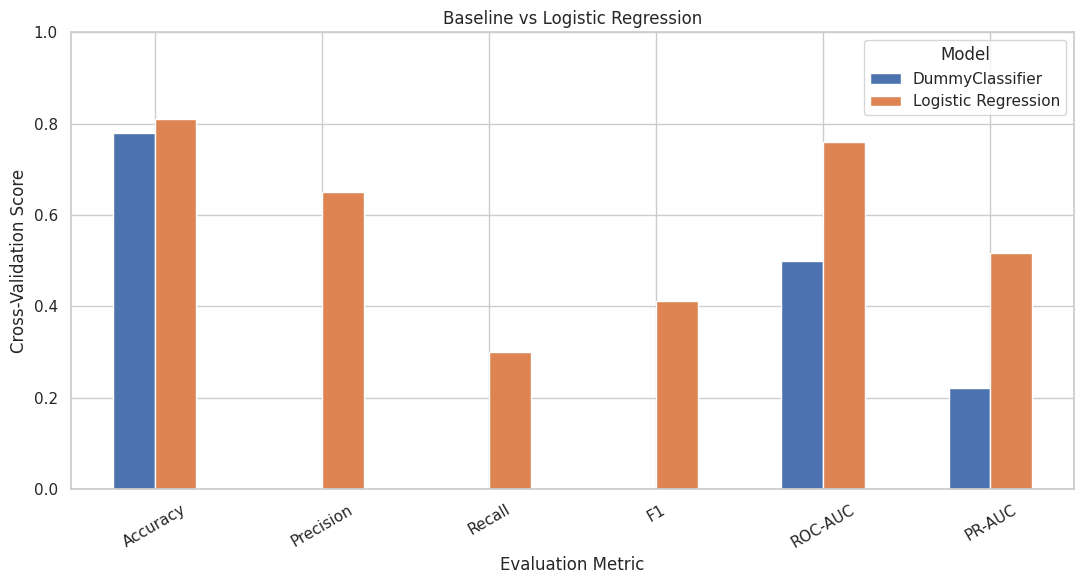

In [141]:
comparison_df.plot(
    kind="bar",
    figsize=(11, 6),
    rot=30
)
plt.title("Baseline vs Logistic Regression")
plt.xlabel("Evaluation Metric")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### 6.6 ROC Curve & Precision-Recall Curve

In [142]:
lr_oof_proba = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [143]:
lr_oof_pred = (lr_oof_proba >= 0.5).astype(int)

In [144]:
print("ROC-AUC:",roc_auc_score(y_train, lr_oof_proba))

ROC-AUC: 0.7590195814656577


In [145]:
print("PR-AUC:",average_precision_score(y_train, lr_oof_proba))

PR-AUC: 0.5135889669371693


In [146]:
print("Brier Score:",brier_score_loss(y_train, lr_oof_proba))

Brier Score: 0.1397126802226949


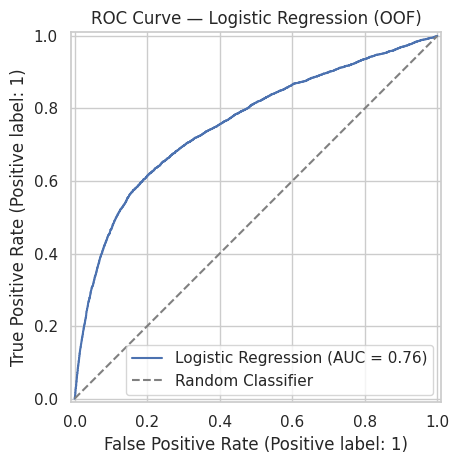

In [147]:
RocCurveDisplay.from_predictions(
    y_train,
    lr_oof_proba,
    name="Logistic Regression"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve — Logistic Regression (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

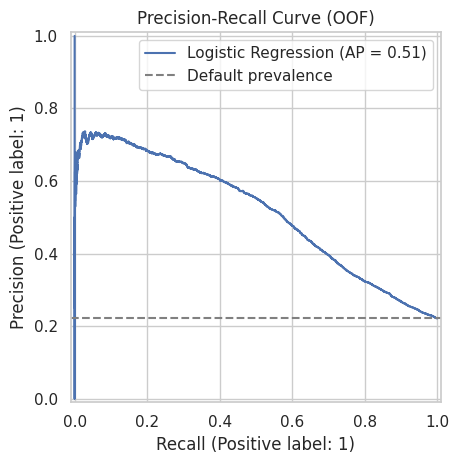

In [148]:
PrecisionRecallDisplay.from_predictions(
    y_train,
    lr_oof_proba,
    name="Logistic Regression"
)

plt.axhline(
    y=y_train.mean(),
    color="gray",
    linestyle="--",
    label="Default prevalence"
)

plt.title("Precision-Recall Curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

### 6.7 Confusion Matrix & Classification Report

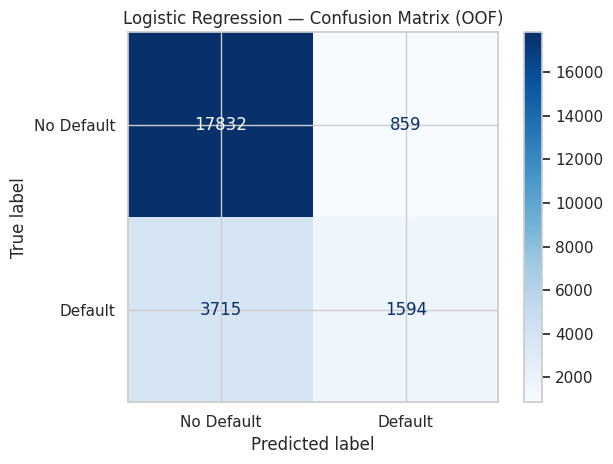

In [149]:
cm = confusion_matrix(
    y_train,
    lr_oof_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression — Confusion Matrix (OOF)")
plt.tight_layout()
plt.show()

In [150]:
print(
    classification_report(
        y_train,
        lr_oof_pred,
        target_names=["No Default", "Default"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Default       0.83      0.95      0.89     18691
     Default       0.65      0.30      0.41      5309

    accuracy                           0.81     24000
   macro avg       0.74      0.63      0.65     24000
weighted avg       0.79      0.81      0.78     24000



The Logistic Regression model achieved an accuracy of approximately 81%, ROC-AUC of 0.759, and PR-AUC of 0.514, demonstrating meaningful predictive performance compared to the baseline. However, while precision reached 65%, recall remained relatively low at 30%, with 3,715 actual default cases incorrectly classified as non-defaulting. The Brier Score of 0.1397 indicates an improvement in probability prediction accuracy over the constant-probability baseline. Overall, Logistic Regression provides a useful benchmark for credit risk prediction, but further evaluation of classification thresholds, probability calibration, and more advanced models is necessary to improve default detection and support reliable Expected Loss estimation.

### 6.8 Random Forest & XGBoost

In [151]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=1
        ))
    ]
)

display(rf_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_0',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AM...
                                                   'PAYMENT_BILL_RATIO']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['SEX', 'EDUCATION',
                                                   'MARRIAGE'])],
                                   verbose_feature_names_out=False)),
                ('classifier',
                 RandomForestClassifier(max_depth=12, min_samples_leaf=5,
                                        n_estimators=200, n_jobs=1,
                                        random_state=42))])

In [152]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=1
        ))
    ]
)

display(xgb_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_0',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AM...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=1,
                               num_parallel_tree=None, ...))])

In [153]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [154]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
    "Brier Score": "neg_brier_score"
}

In [155]:
models = {
    "DummyClassifier": DummyClassifier(strategy="prior"),
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

In [156]:
cv_results = []
for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    result = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        if metric == "Brier Score":
            values = -values
        result[metric] = values.mean()
        result[f"{metric} Std"] = values.std()
    cv_results.append(result)

In [157]:
cv_df = pd.DataFrame(cv_results)
display(
    cv_df[
        ["Model", "Accuracy", "Precision",
         "Recall", "F1", "ROC-AUC",
         "PR-AUC", "Brier Score"]
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
0,DummyClassifier,0.78,0.00,0.00,0.00,0.50,0.22,0.17
1,Logistic Regression,0.81,0.65,0.30,0.41,0.76,0.52,0.14
2,Random Forest,0.82,0.67,0.37,0.48,0.78,0.56,0.13
3,XGBoost,0.82,0.67,0.37,0.48,0.79,0.56,0.13


In [158]:
metrics = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

In [159]:
comparison = cv_df.set_index("Model")[metrics].T

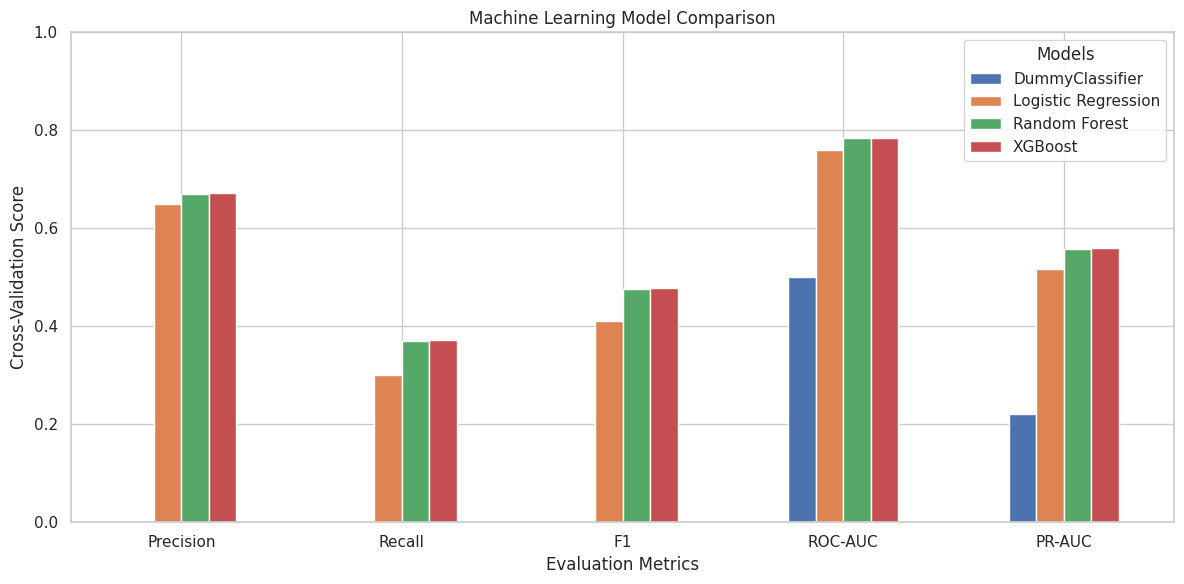

In [160]:
comparison.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.legend(title="Models")
plt.tight_layout()
plt.show()

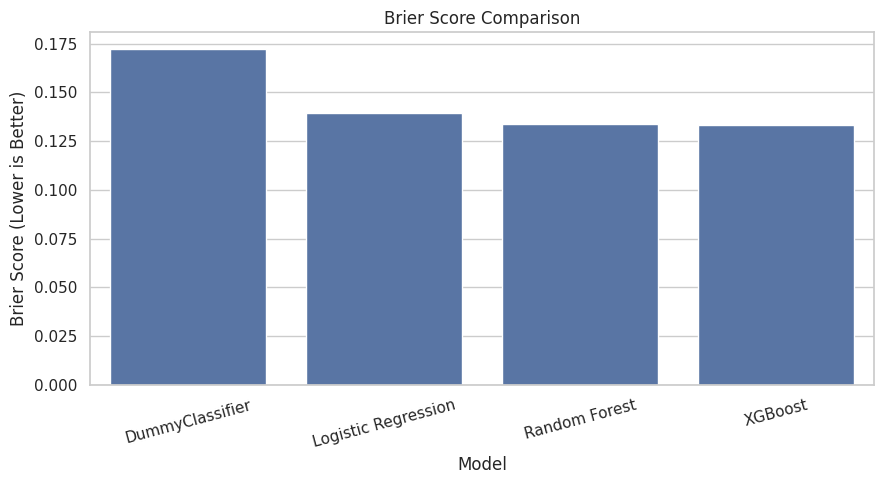

In [161]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Brier Score"
)

plt.title("Brier Score Comparison")
plt.xlabel("Model")
plt.ylabel("Brier Score (Lower is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

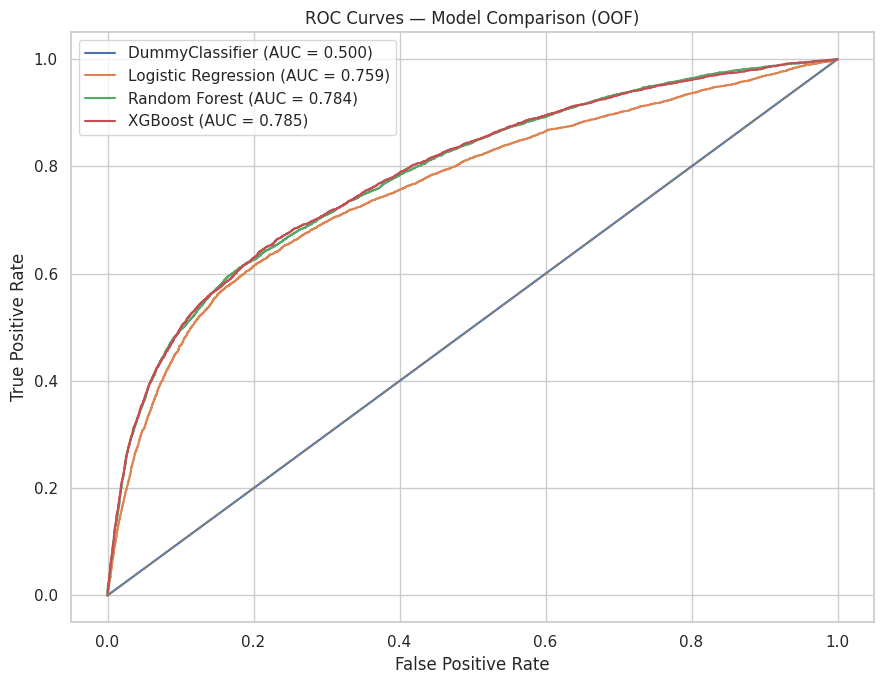

In [162]:
oof_probabilities = {}
plt.figure(figsize=(9, 7))

for name, model in models.items():

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = probabilities

    fpr, tpr, thresholds = roc_curve(
        y_train,
        probabilities
    )

    auc = roc_auc_score(
        y_train,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curves — Model Comparison (OOF)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

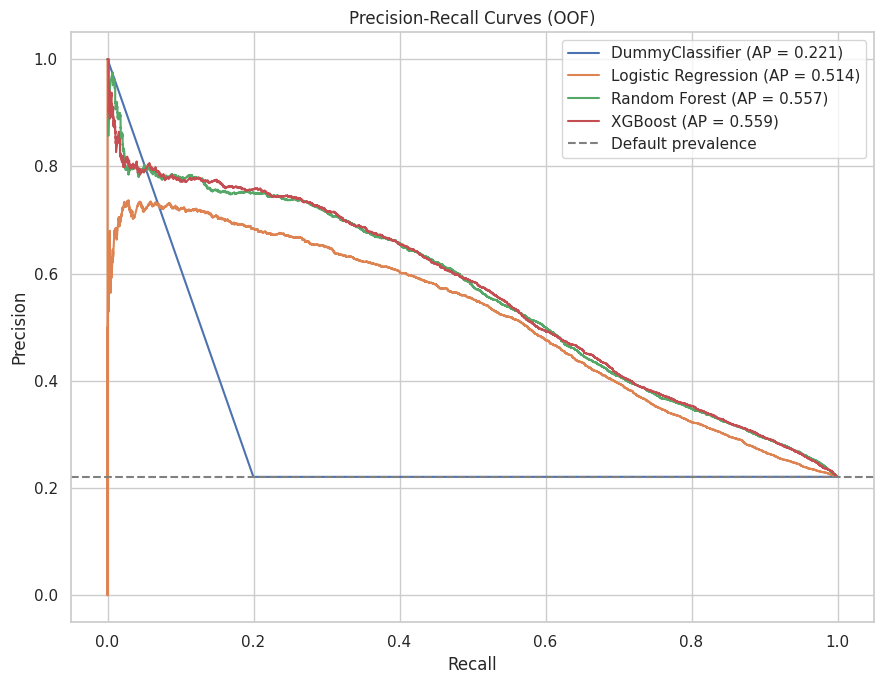

In [163]:
plt.figure(figsize=(9, 7))
for name, probabilities in oof_probabilities.items():
    precision, recall, thresholds = (
        precision_recall_curve(
            y_train,
            probabilities
        )
    )

    ap = average_precision_score(
        y_train,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.axhline(
    y=y_train.mean(),
    color="gray",
    linestyle="--",
    label="Default prevalence"
)

plt.title("Precision-Recall Curves (OOF)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

In [164]:
model_ranking = cv_df[
    ["Model", "ROC-AUC", "PR-AUC",
     "Recall", "F1", "Brier Score"]
].sort_values(
    by="PR-AUC",
    ascending=False
)

display(model_ranking.round(4))

,Model,ROC-AUC,PR-AUC,Recall,F1,Brier Score
3,XGBoost,0.79,0.56,0.37,0.48,0.13
2,Random Forest,0.78,0.56,0.37,0.48,0.13
1,Logistic Regression,0.76,0.52,0.30,0.41,0.14
0,DummyClassifier,0.50,0.22,0.00,0.00,0.17


Random Forest and XGBoost outperformed Logistic Regression across the main evaluation metrics, achieving ROC-AUC scores of approximately 0.784–0.785 and PR-AUC scores of 0.557–0.559. Both models improved default detection, increasing Recall from 30% to approximately 37% and F1-score from 0.41 to 0.48. XGBoost achieved marginally better discrimination and probability prediction performance, although its results were nearly identical to Random Forest. The lower Brier Scores of both models also suggest improved probabilistic accuracy compared to Logistic Regression. Overall, Random Forest and XGBoost are promising candidates for further optimization, probability calibration, and Expected Loss analysis.

### 6.9 Hyperparameter Tuning - Random Forest & XGBoost

In [165]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [166]:
rf_param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [6, 10, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [None, "balanced"]
}

In [167]:
rf_search = RandomizedSearchCV(
    estimator=clone(rf_pipeline),
    param_distributions=rf_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [168]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(add_indicator=True,
                                                                                                              strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['LIMIT_BAL',
                                                                                'AGE',
                                                                                'PAY_0',
                                                                                'PAY_2',
                                                                                'PAY_3',
                                                                                'PAY_4',
                                                                                'PAY_5',
                                                                                'PAY_6',
                                                                                'BILL_AMT1',...
                                                                     random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'classifier__class_weight': [None,
                                                                     'balanced'],
                                        'classifier__max_depth': [6, 10, 15, 20,
                                                                  None],
                                        'classifier__max_features': ['sqrt',
                                                                     'log2'],
                                        'classifier__min_samples_leaf': [2, 5,
                                                                         10],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     300]},
                   random_state=42, scoring='average_precision', verbose=1)

In [169]:
print("Best Random Forest Parameters:")
print(rf_search.best_params_)

Best Random Forest Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__class_weight': None}


In [170]:
print("Best Cross-Validation PR-AUC:",round(rf_search.best_score_, 4))

Best Cross-Validation PR-AUC: 0.562


In [171]:
rf_results = pd.DataFrame(
    rf_search.cv_results_
)

rf_results = rf_results[
    ["rank_test_score",
     "mean_test_score",
     "std_test_score",
     "params"]
].sort_values("rank_test_score")

display(rf_results.head(10))

,rank_test_score,mean_test_score,std_test_score,params
3,1,0.56,0.01,"{'classifier__n_estimators': 300, 'classifier_..."
19,2,0.56,0.01,"{'classifier__n_estimators': 200, 'classifier_..."
5,3,0.56,0.01,"{'classifier__n_estimators': 300, 'classifier_..."
1,4,0.56,0.01,"{'classifier__n_estimators': 200, 'classifier_..."
13,5,0.56,0.01,"{'classifier__n_estimators': 100, 'classifier_..."
17,6,0.56,0.01,"{'classifier__n_estimators': 300, 'classifier_..."
10,7,0.56,0.01,"{'classifier__n_estimators': 100, 'classifier_..."
8,8,0.56,0.01,"{'classifier__n_estimators': 100, 'classifier_..."
11,9,0.56,0.01,"{'classifier__n_estimators': 100, 'classifier_..."
7,10,0.56,0.01,"{'classifier__n_estimators': 200, 'classifier_..."


In [172]:
xgb_param_distributions = {
    "classifier__n_estimators": [150, 250, 350, 500],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__reg_lambda": [1, 5, 10]
}

In [173]:
xgb_search = RandomizedSearchCV(
    estimator=clone(xgb_pipeline),
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [174]:
xgb_search.fit(X_train, y_train)


Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(add_indicator=True,
                                                                                                              strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['LIMIT_BAL',
                                                                                'AGE',
                                                                                'PAY_0',
                                                                                'PAY_2',
                                                                                'PAY_3',
                                                                                'PAY_4',
                                                                                'PAY_5',
                                                                                'PAY_6',
                                                                                'BILL_AMT1',...
                   param_distributions={'classifier__colsample_bytree': [0.7,
                                                                         0.8,
                                                                         1.0],
                                        'classifier__learning_rate': [0.01,
                                                                      0.03,
                                                                      0.05,
                                                                      0.1],
                                        'classifier__max_depth': [3, 4, 5, 6],
                                        'classifier__min_child_weight': [1, 3,
                                                                         5],
                                        'classifier__n_estimators': [150, 250,
                                                                     350, 500],
                                        'classifier__reg_lambda': [1, 5, 10],
                                        'classifier__subsample': [0.7, 0.8,
                                                                  1.0]},
                   random_state=42, scoring='average_precision', verbose=1)

In [175]:
print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

Best XGBoost Parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 1, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 5, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 1.0}


In [176]:
print("Best Cross-Validation PR-AUC:",round(xgb_search.best_score_, 4))

Best Cross-Validation PR-AUC: 0.5651


In [177]:
xgb_results = pd.DataFrame(xgb_search.cv_results_)

In [178]:
xgb_results = xgb_results[
    ["rank_test_score",
     "mean_test_score",
     "std_test_score",
     "params"]
].sort_values("rank_test_score")

In [179]:
display(xgb_results.head(10))

,rank_test_score,mean_test_score,std_test_score,params
1,1,0.57,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."
8,2,0.56,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."
11,3,0.56,0.01,"{'classifier__subsample': 0.7, 'classifier__re..."
17,4,0.56,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."
10,5,0.56,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."
15,6,0.56,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."
0,7,0.56,0.01,"{'classifier__subsample': 1.0, 'classifier__re..."
12,8,0.56,0.01,"{'classifier__subsample': 0.7, 'classifier__re..."
7,9,0.56,0.01,"{'classifier__subsample': 0.7, 'classifier__re..."
3,10,0.56,0.01,"{'classifier__subsample': 0.8, 'classifier__re..."


In [180]:
original_rf = cv_df.loc[
    cv_df["Model"] == "Random Forest",
    "PR-AUC"
].iloc[0]

In [181]:
original_xgb = cv_df.loc[
    cv_df["Model"] == "XGBoost",
    "PR-AUC"
].iloc[0]

In [182]:
tuning_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Before Tuning": [original_rf, original_xgb],
    "After Tuning": [
        rf_search.best_score_,
        xgb_search.best_score_
    ]
})

In [183]:
tuning_comparison["Improvement"] = (
    tuning_comparison["After Tuning"]
    - tuning_comparison["Before Tuning"]
)

In [184]:
display(tuning_comparison.round(4))

,Model,Before Tuning,After Tuning,Improvement
0,Random Forest,0.56,0.56,0.00
1,XGBoost,0.56,0.57,0.01


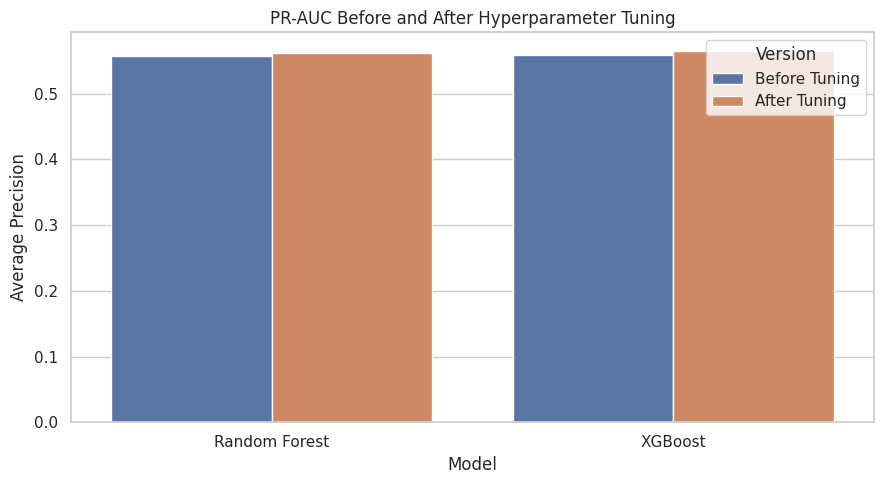

In [185]:
plot_df = tuning_comparison.melt(
    id_vars="Model",
    value_vars=["Before Tuning", "After Tuning"],
    var_name="Version",
    value_name="PR-AUC"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_df,
    x="Model",
    y="PR-AUC",
    hue="Version"
)

plt.title("PR-AUC Before and After Hyperparameter Tuning")
plt.xlabel("Model")
plt.ylabel("Average Precision")
plt.tight_layout()
plt.show()

In [186]:
best_rf = rf_search.best_estimator_
best_xgb = xgb_search.best_estimator_
print("Optimized models saved successfully!")

Optimized models saved successfully!


In [187]:
if rf_search.best_score_ > xgb_search.best_score_:
    candidate_model = best_rf
    candidate_name = "Random Forest"
else:
    candidate_model = best_xgb
    candidate_name = "XGBoost"

print("Selected candidate:", candidate_name)

Selected candidate: XGBoost




Hyperparameter optimization resulted in a modest improvement in model performance, with XGBoost achieving the highest cross-validation PR-AUC of approximately 0.57. The optimized XGBoost configuration uses 500 estimators, a learning rate of 0.01, and a maximum tree depth of 5, balancing gradual learning with model complexity. Random Forest showed minimal improvement following optimization. Overall, XGBoost was selected as the leading candidate for probability calibration and further evaluation, although its performance advantage remains small and requires independent validation.

## 7. Probability Calibration - XGBoost

### 7.1 Compare Calibration Before and After

In [188]:
uncalibrated_model = clone(best_xgb)

In [189]:
calibrated_model = CalibratedClassifierCV(
    estimator=clone(best_xgb),
    method="sigmoid",
    cv=3
)

In [190]:
calibration_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [191]:
uncalibrated_proba = cross_val_predict(
    uncalibrated_model,
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [192]:
calibrated_proba = cross_val_predict(
    calibrated_model,
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [193]:
calibration_results = pd.DataFrame({
    "Model": [
        "XGBoost (Uncalibrated)",
        "XGBoost (Calibrated)"
    ],
    "Brier Score": [
        brier_score_loss(y_train, uncalibrated_proba),
        brier_score_loss(y_train, calibrated_proba)
    ],
    "Log Loss": [
        log_loss(y_train, uncalibrated_proba),
        log_loss(y_train, calibrated_proba)
    ],
    "ROC-AUC": [
        roc_auc_score(y_train, uncalibrated_proba),
        roc_auc_score(y_train, calibrated_proba)
    ],
    "PR-AUC": [
        average_precision_score(y_train, uncalibrated_proba),
        average_precision_score(y_train, calibrated_proba)
    ]
})

In [194]:
display(calibration_results.round(5))

,Model,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,XGBoost (Uncalibrated),0.13,0.42,0.79,0.56
1,XGBoost (Calibrated),0.13,0.43,0.79,0.56


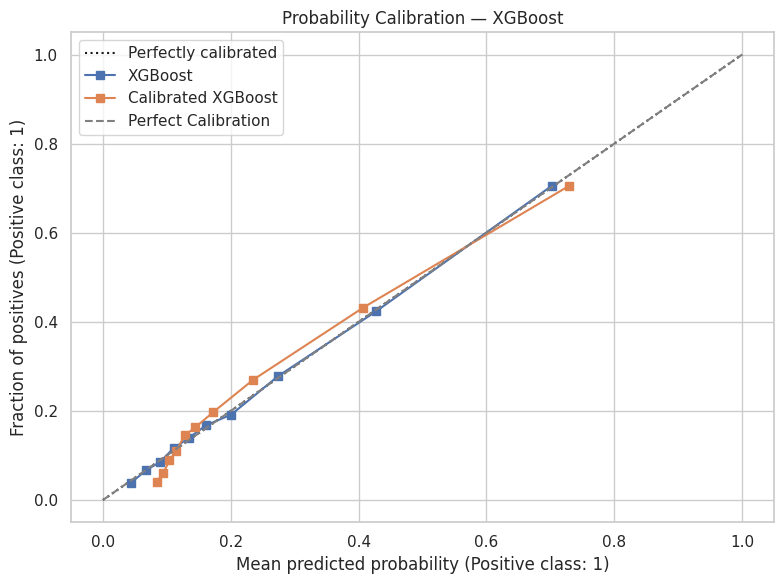

In [195]:
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_train,
    uncalibrated_proba,
    n_bins=10,
    strategy="quantile",
    name="XGBoost",
    ax=ax
)
CalibrationDisplay.from_predictions(
    y_train,
    calibrated_proba,
    n_bins=10,
    strategy="quantile",
    name="Calibrated XGBoost",
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

ax.set_title("Probability Calibration — XGBoost")
ax.legend()
plt.tight_layout()
plt.show()

In [196]:
final_calibrated_xgb = clone(calibrated_model)
final_calibrated_xgb.fit(X_train, y_train)
print("Calibrated XGBoost trained successfully!")

Calibrated XGBoost trained successfully!


The optimized XGBoost model demonstrated reasonably good probability calibration, with predicted default probabilities closely aligned with observed default rates. Sigmoid calibration did not improve the Brier Score or discrimination metrics and resulted in a slightly higher Log Loss. Therefore, the original optimized XGBoost model was retained as the preferred candidate for Probability of Default estimation. However, calibration in high-risk probability ranges remains less certain and requires further validation.

###6.10 LightGBM and CatBoost Classifier

In [197]:
lgbm_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=20,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ))
])

In [198]:
catboost_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=5,
        loss_function="Logloss",
        random_seed=42,
        verbose=False,
        thread_count=1
    ))
])

In [199]:
new_models = {"LightGBM": lgbm_pipeline,"CatBoost": catboost_pipeline}

In [200]:
new_results = []

for name, model in new_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]

        if metric == "Brier Score":
            values = -values

        result[metric] = values.mean()

    new_results.append(result)

new_df = pd.DataFrame(new_results)

In [201]:
display(new_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
0,LightGBM,0.82,0.68,0.38,0.48,0.78,0.56,0.13
1,CatBoost,0.82,0.68,0.37,0.48,0.79,0.56,0.13


In [202]:
all_models_df = pd.concat(
    [
        cv_df.drop_duplicates(subset="Model"),
        new_df
    ],
    ignore_index=True
)

In [203]:
all_models_df = all_models_df.sort_values(
    by="PR-AUC",
    ascending=False
)

In [204]:
display(
    all_models_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "Brier Score"
        ]
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
5,CatBoost,0.82,0.68,0.37,0.48,0.79,0.56,0.13
4,LightGBM,0.82,0.68,0.38,0.48,0.78,0.56,0.13
3,XGBoost,0.82,0.67,0.37,0.48,0.79,0.56,0.13
2,Random Forest,0.82,0.67,0.37,0.48,0.78,0.56,0.13
1,Logistic Regression,0.81,0.65,0.30,0.41,0.76,0.52,0.14
0,DummyClassifier,0.78,0.00,0.00,0.00,0.50,0.22,0.17


LightGBM and CatBoost were evaluated alongside Logistic Regression, Random Forest, and XGBoost using stratified 5-fold cross-validation. The gradient boosting models demonstrated comparable predictive performance, achieving approximately 0.78–0.79 ROC-AUC, 0.56 PR-AUC, and 0.48 F1-score. LightGBM achieved slightly higher recall, while CatBoost showed competitive precision and discrimination performance. However, the differences between the boosting models were small and do not establish a clear superiority of one algorithm. The optimized XGBoost model was retained as the leading candidate for further evaluation, with CatBoost considered as an alternative.

## 7. Classification Threshold Optimization — XGBoost

### 7.1 Generate Out-of-Fold Predictions

In [205]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [206]:
xgb_oof_proba = cross_val_predict(
    clone(best_xgb),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [207]:
print("OOF predictions generated!")
print("Number of predictions:", len(xgb_oof_proba))

OOF predictions generated!
Number of predictions: 24000


### 7.2 Evaluate Different Thresholds

In [208]:
thresholds = np.round(
    np.arange(0.10, 0.71, 0.05),
    2
)

In [209]:
threshold_results = []

for threshold in thresholds:

    predictions = (
        xgb_oof_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

In [210]:
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,True Positives,False Positives,True Negatives,False Negatives
0,0.10,0.29,0.91,0.44,4847,11934,6757,462
1,0.15,0.36,0.79,0.49,4200,7555,11136,1109
2,0.20,0.43,0.68,0.53,3609,4696,13995,1700
3,0.25,0.49,0.61,0.54,3219,3301,15390,2090
4,0.30,0.54,0.55,0.54,2920,2515,16176,2389
5,0.35,0.59,0.50,0.54,2632,1841,16850,2677
6,0.40,0.63,0.44,0.52,2358,1391,17300,2951
7,0.45,0.66,0.41,0.50,2151,1114,17577,3158
8,0.50,0.68,0.37,0.48,1960,924,17767,3349
9,0.55,0.70,0.33,0.45,1774,761,17930,3535


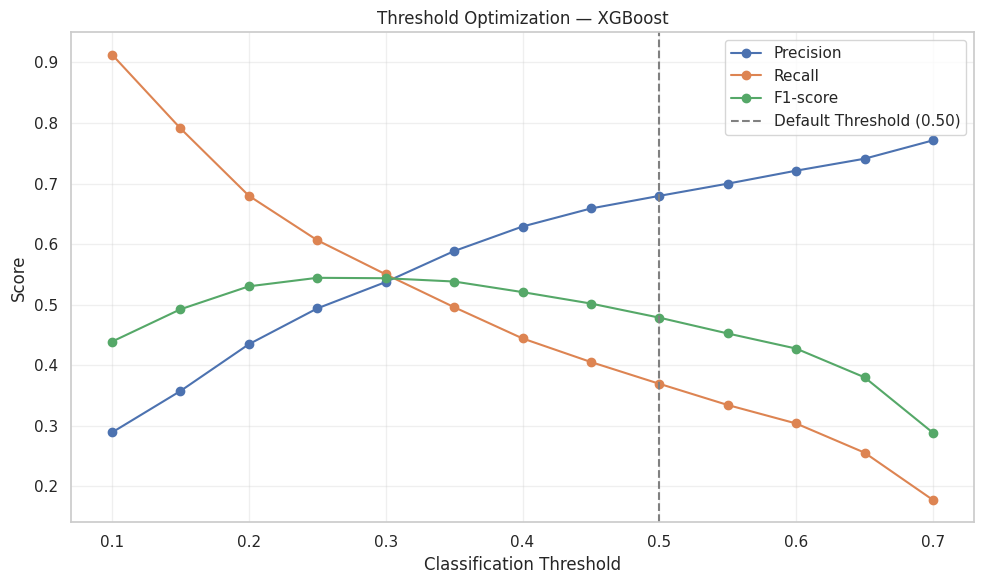

In [211]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    0.50,
    linestyle="--",
    color="gray",
    label="Default Threshold (0.50)"
)

plt.title("Threshold Optimization — XGBoost")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.4 Select the Optimal Threshold

In [212]:
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

optimal_threshold = float(best_row["Threshold"])

print(f"Optimal Threshold: {optimal_threshold:.2f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1-score: {best_row['F1']:.4f}")
print(f"False Negatives: {int(best_row['False Negatives'])}")
print(f"False Positives: {int(best_row['False Positives'])}")

Optimal Threshold: 0.25
Precision: 0.4937
Recall: 0.6063
F1-score: 0.5443
False Negatives: 2090
False Positives: 3301


### 7.5 Compare Default vs Optimized Threshold

In [213]:
comparison_results = []

for name, threshold in [
    ("Default Threshold", 0.50),
    ("Optimized Threshold", optimal_threshold)
]:

    predictions = (
        xgb_oof_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions,
        labels=[0, 1]
    ).ravel()

    comparison_results.append({
        "Method": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_comparison = pd.DataFrame(comparison_results)

In [214]:
display(threshold_comparison.round(4))

,Method,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,Default Threshold,0.50,0.68,0.37,0.48,924,3349
1,Optimized Threshold,0.25,0.49,0.61,0.54,3301,2090


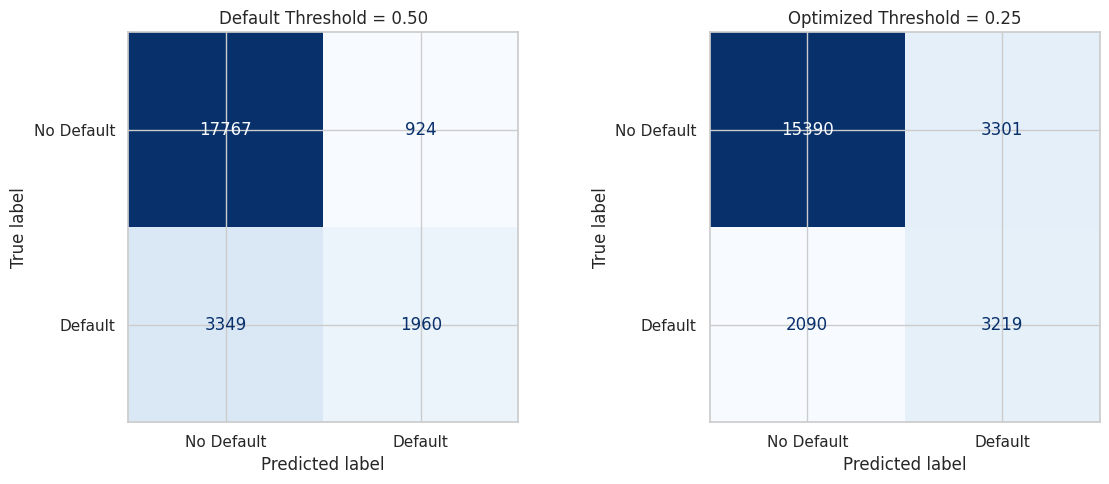

In [215]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, threshold) in zip(
    axes,
    [
        ("Default Threshold", 0.50),
        ("Optimized Threshold", optimal_threshold)
    ]
):

    predictions = (
        xgb_oof_proba >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        display_labels=["No Default", "Default"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} = {threshold:.2f}")

plt.tight_layout()
plt.show()

Threshold optimization identified 0.25 as the F1-optimal threshold among the evaluated candidates, improving Recall from 36.9% to 60.6% and F1-score from 0.478 to 0.544. This adjustment enabled the XGBoost model to identify 1,259 additional default cases and reduce false negatives from 3,349 to 2,090. However, Precision decreased from approximately 68.0% to 49.4%, accompanied by a substantial increase in false positives. These findings demonstrate the trade-off between detecting credit defaults and incorrectly flagging non-defaulting clients. The 0.25 threshold was selected for final evaluation as an illustrative F1-oriented decision rule, while its suitability for real lending decisions would require cost-based analysis.

## 8. Final Model Evaluation - Optimized XGBoost

### 8.1 Generate Final Test Predictions

In [216]:
final_model = best_xgb

In [217]:
final_threshold = 0.25

In [218]:
y_test_proba = final_model.predict_proba(X_test)[:, 1]

In [219]:
y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)

In [220]:
print("Test observations:", len(y_test))

Test observations: 6000


In [221]:
print("Classification threshold:", final_threshold)

Classification threshold: 0.25


In [222]:
print("Predicted classes:")
print(pd.Series(y_test_pred).value_counts())

Predicted classes:
0    4389
1    1611
Name: count, dtype: int64


### 8.2  Calculate Final Evaluation Metrics

In [223]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1-score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba),
    "PR-AUC": average_precision_score(
        y_test, y_test_proba
    ),
    "Brier Score": brier_score_loss(
        y_test, y_test_proba
    ),
    "Log Loss": log_loss(y_test, y_test_proba)
}


In [224]:
final_metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Test Score"]
)


In [225]:
display(final_metrics_df.round(4))

,Metric,Test Score
0,Accuracy,0.78
1,Precision,0.50
2,Recall,0.61
3,F1-score,0.55
4,ROC-AUC,0.78
5,PR-AUC,0.56
6,Brier Score,0.13
7,Log Loss,0.43


### 8.3 Final Confusion Matrix

In [226]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

In [227]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

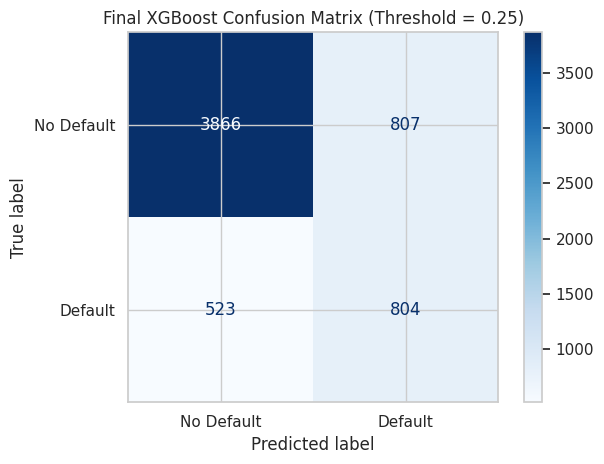

In [228]:
disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Final XGBoost Confusion Matrix "
    f"(Threshold = {final_threshold})"
)

plt.tight_layout()
plt.show()

In [229]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nMissed Default Rate:",
      round(fn / (fn + tp) * 100, 2), "%")

print("False Positive Rate:",
      round(fp / (fp + tn) * 100, 2), "%")

True Negatives: 3866
False Positives: 807
False Negatives: 523
True Positives: 804

Missed Default Rate: 39.41 %
False Positive Rate: 17.27 %


### 8.4 Final Classification Report

In [230]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No Default", "Default"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Default     0.8808    0.8273    0.8532      4673
     Default     0.4991    0.6059    0.5473      1327

    accuracy                         0.7783      6000
   macro avg     0.6900    0.7166    0.7003      6000
weighted avg     0.7964    0.7783    0.7856      6000



### 8.5 ROC Curve — Final Test Set

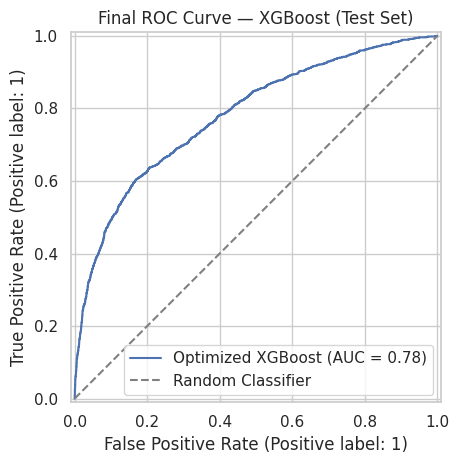

In [231]:
RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name="Optimized XGBoost"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("Final ROC Curve — XGBoost (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

### 8.6 Precision-Recall Curve - Final Test Set

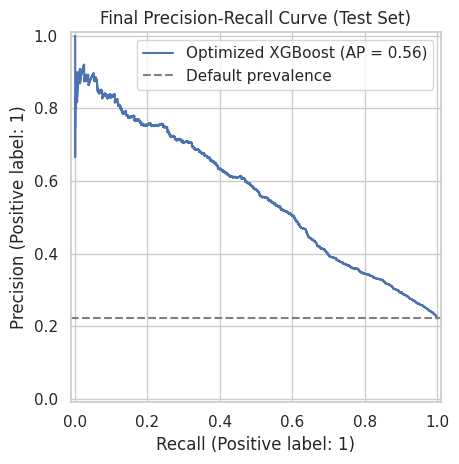

In [232]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_proba,
    name="Optimized XGBoost"
)

plt.axhline(
    y=y_test.mean(),
    color="gray",
    linestyle="--",
    label="Default prevalence"
)

plt.title("Final Precision-Recall Curve (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

### 8.7 Final Probability Calibration Curve

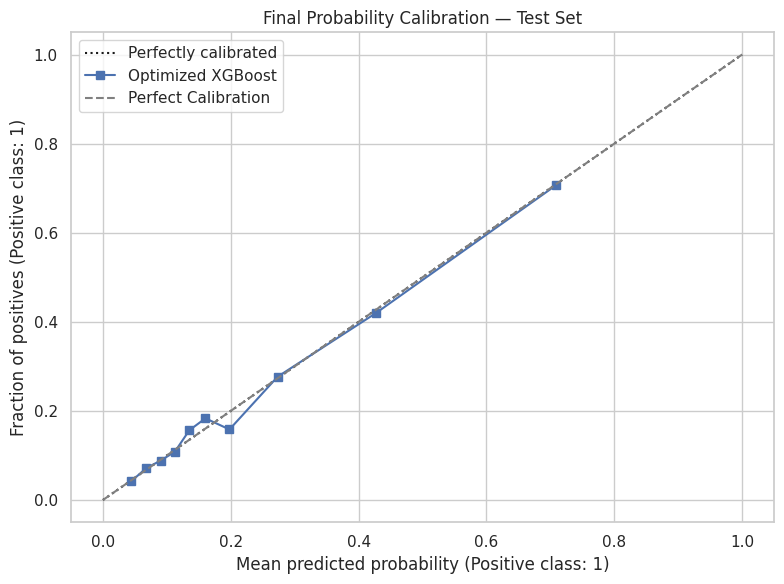

In [233]:
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    y_test_proba,
    n_bins=10,
    strategy="quantile",
    name="Optimized XGBoost",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

ax.set_title(
    "Final Probability Calibration — Test Set"
)

ax.legend()
plt.tight_layout()
plt.show()

### 8.8 Compare Validation and Test Performance

In [234]:
oof_pred = (
    xgb_oof_proba >= final_threshold
).astype(int)

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Brier Score"
    ],

    "OOF Validation": [
        accuracy_score(y_train, oof_pred),
        precision_score(y_train, oof_pred),
        recall_score(y_train, oof_pred),
        f1_score(y_train, oof_pred),
        roc_auc_score(y_train, xgb_oof_proba),
        average_precision_score(y_train, xgb_oof_proba),
        brier_score_loss(y_train, xgb_oof_proba)
    ],

    "Test Set": [
        final_metrics["Accuracy"],
        final_metrics["Precision"],
        final_metrics["Recall"],
        final_metrics["F1-score"],
        final_metrics["ROC-AUC"],
        final_metrics["PR-AUC"],
        final_metrics["Brier Score"]
    ]
})


In [235]:
comparison["Difference (Test - OOF)"] = (
    comparison["Test Set"] - comparison["OOF Validation"]
)


In [236]:
display(comparison.round(4))

,Metric,OOF Validation,Test Set,Difference (Test - OOF)
0,Accuracy,0.78,0.78,0.00
1,Precision,0.49,0.50,0.01
2,Recall,0.61,0.61,-0.00
3,F1,0.54,0.55,0.00
4,ROC-AUC,0.79,0.78,-0.01
5,PR-AUC,0.56,0.56,-0.00
6,Brier Score,0.13,0.13,0.00


The optimized XGBoost model achieved an accuracy of 77.8%, Precision of 49.9%, Recall of 60.6%, and F1-score of 0.547 on the held-out test set using the selected threshold of 0.25. The model correctly identified 804 of 1,327 default cases while generating 807 false positives. ROC-AUC (0.78) and PR-AUC (0.56) demonstrated consistent discrimination performance, while the Brier Score (0.13) and calibration curve indicated reasonably reliable probability estimates. The similarity between validation and test results suggests satisfactory generalization, although some default cases remain undetected. Overall, the model provides a suitable foundation for illustrative Probability of Default and Expected Loss analysis.

## 9. Expected Loss Analysis - Credit Risk

### 9.1 Define LGD and EAD Assumptions

In [237]:
risk_df = X_test.copy()

In [238]:
risk_df["ACTUAL_DEFAULT"] = y_test.to_numpy()
risk_df["PD"] = y_test_proba

In [239]:
assert len(risk_df) == len(y_test_proba)
assert risk_df["PD"].between(0, 1).all()
assert (risk_df["LIMIT_BAL"] > 0).all()

In [240]:
display(risk_df.head())

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,AVG_BILL,AVG_PAYMENT,AVG_UTILIZATION,MONTHS_DELAYED,MAX_DELAY,PAYMENT_BILL_RATIO,ACTUAL_DEFAULT,PD
6907,50000,1,2,2,46,-1,-1,-1,-1,0,0,1540,26060,0,2650,3320,2764,26060,0,3472,2320,1764,2841,6055.67,6076.17,0.12,0,0,16.92,0,0.13
24575,150000,1,1,1,31,-1,-1,-2,-2,-2,-1,15000,0,0,0,0,11694,0,0,0,0,11694,30000,4449.00,6949.00,0.03,0,-1,0.00,0,0.14
26766,50000,1,2,2,25,0,0,0,0,0,0,48065,48355,49009,49949,50479,50702,1800,1844,2200,2000,1800,2038,49426.50,1947.00,0.99,0,0,0.04,0,0.17
2156,290000,2,1,2,25,0,0,0,0,0,0,305823,303701,296384,248801,241983,230925,15000,10500,10000,15000,7844,23333,271269.50,13612.83,0.94,0,0,0.05,1,0.14
3179,500000,2,2,1,27,-2,-2,-2,-2,-2,-2,11354,9983,13570,10000,10000,10000,9983,13587,10000,10000,10000,25304,10817.83,13145.67,0.02,0,-2,0.88,0,0.04


In [241]:
LGD_ASSUMPTION = 0.45
EAD_FACTOR = 0.50

In [242]:
risk_df["LGD"] = LGD_ASSUMPTION

In [243]:
risk_df["EAD"] = (
    risk_df["LIMIT_BAL"] * EAD_FACTOR
)

In [244]:
risk_df["EXPECTED_LOSS"] = (
    risk_df["PD"]
    * risk_df["LGD"]
    * risk_df["EAD"]
)

In [245]:
display(risk_df[["LIMIT_BAL", "PD", "LGD", "EAD", "EXPECTED_LOSS"]].head(10).round(2))

,LIMIT_BAL,PD,LGD,EAD,EXPECTED_LOSS
6907,50000,0.13,0.45,25000.00,1473.62
24575,150000,0.14,0.45,75000.00,4727.56
26766,50000,0.17,0.45,25000.00,1881.37
2156,290000,0.14,0.45,145000.00,9048.24
3179,500000,0.04,0.45,250000.00,4337.51
29382,200000,0.43,0.45,100000.00,19126.15
24454,210000,0.11,0.45,105000.00,5064.06
23886,260000,0.03,0.45,130000.00,1846.37
5504,450000,0.10,0.45,225000.00,10310.25
29720,150000,0.07,0.45,75000.00,2351.32


### 9.2 Portfolio Expected Loss

In [246]:
portfolio_summary = pd.DataFrame({
    "Metric": [
        "Number of Clients",
        "Total Credit Limits (NTD)",
        "Total Assumed EAD (NTD)",
        "Average PD (%)",
        "EAD-Weighted PD (%)",
        "Assumed LGD (%)",
        "Total Expected Loss (NTD)",
        "Average Expected Loss per Client (NTD)",
        "Expected Loss / Total EAD (%)"
    ],
    "Value": [
        len(risk_df),
        risk_df["LIMIT_BAL"].sum(),
        risk_df["EAD"].sum(),
        risk_df["PD"].mean() * 100,
        (
            (risk_df["PD"] * risk_df["EAD"]).sum()
            / risk_df["EAD"].sum() * 100
        ),
        LGD_ASSUMPTION * 100,
        risk_df["EXPECTED_LOSS"].sum(),
        risk_df["EXPECTED_LOSS"].mean(),
        (
            risk_df["EXPECTED_LOSS"].sum()
            / risk_df["EAD"].sum() * 100
        )
    ]
})

In [247]:
display(portfolio_summary.round(2))

,Metric,Value
0,Number of Clients,6000.00
1,Total Credit Limits (NTD),1007777680.00
2,Total Assumed EAD (NTD),503888840.00
3,Average PD (%),22.18
4,EAD-Weighted PD (%),17.18
5,Assumed LGD (%),45.00
6,Total Expected Loss (NTD),38961942.99
7,Average Expected Loss per Client (NTD),6493.66
8,Expected Loss / Total EAD (%),7.73


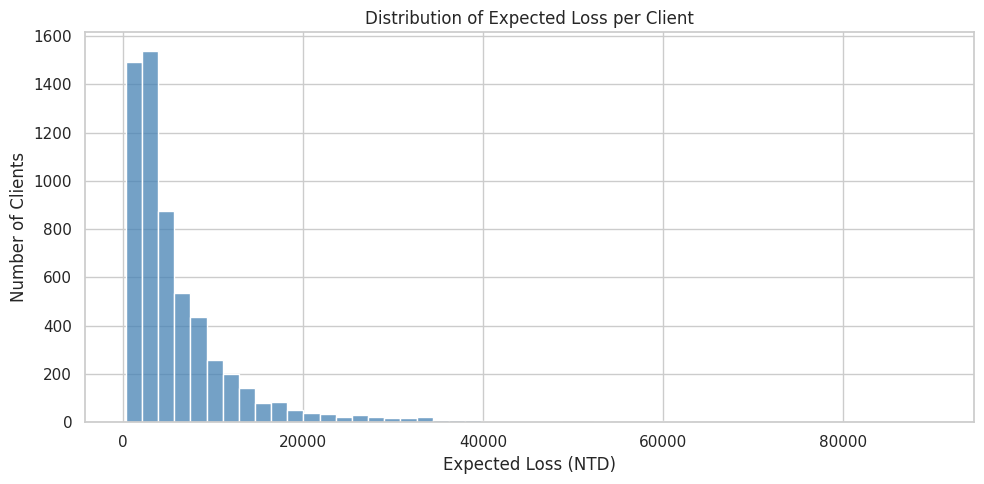

In [248]:
plt.figure(figsize=(10, 5))

sns.histplot(
    risk_df["EXPECTED_LOSS"],
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Expected Loss per Client")
plt.xlabel("Expected Loss (NTD)")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()

### 9.3 Expected Loss by Risk Segment

In [249]:
risk_df["RISK_CATEGORY"] = pd.cut(
    risk_df["PD"],
    bins=[0, 0.10, 0.25, 0.50, 1.0],
    labels=[
        "Low Risk",
        "Moderate Risk",
        "High Risk",
        "Very High Risk"
    ],
    include_lowest=True
)

In [250]:
risk_summary = (
    risk_df.groupby("RISK_CATEGORY", observed=True)
    .agg(
        Clients=("PD", "count"),
        Average_PD=("PD", "mean"),
        Actual_Default_Rate=("ACTUAL_DEFAULT", "mean"),
        Total_EAD=("EAD", "sum"),
        Total_Expected_Loss=("EXPECTED_LOSS", "sum")
    )
)
risk_summary["Average_PD"] *= 100
risk_summary["Actual_Default_Rate"] *= 100
risk_summary["Share_of_Total_EL"] = (
    risk_summary["Total_Expected_Loss"]
    / risk_df["EXPECTED_LOSS"].sum() * 100
)


In [251]:
display(risk_summary.round(2))

,Clients,Average_PD,Actual_Default_Rate,Total_EAD,Total_Expected_Loss,Share_of_Total_EL
RISK_CATEGORY,,,,,,
Low Risk,1769,6.68,6.73,219470000.00,6180403.62,15.86
Moderate Risk,2620,15.71,15.42,193688840.00,13153626.37,33.76
High Risk,893,34.93,36.17,54515000.00,8399613.79,21.56
Very High Risk,718,68.11,66.99,36215000.00,11228299.21,28.82


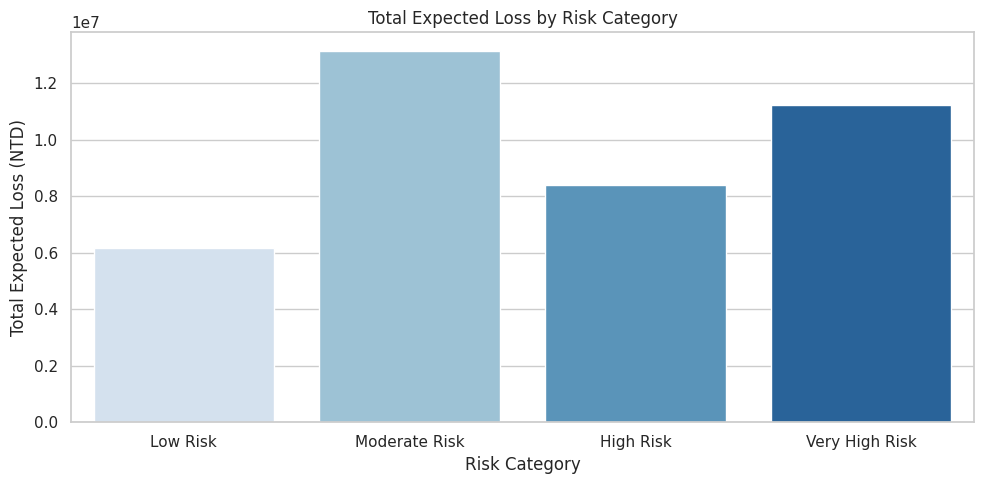

In [252]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=risk_summary.reset_index(),
    x="RISK_CATEGORY",
    y="Total_Expected_Loss",
    hue="RISK_CATEGORY",
    palette="Blues",
    legend=False
)
plt.title("Total Expected Loss by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Total Expected Loss (NTD)")
plt.tight_layout()
plt.show()

### 9.4 Scenario Analysis - Optimistic, Base and Stress

In [253]:
scenarios = {
    "Optimistic": {
        "LGD": 0.30,
        "EAD_Factor": 0.30
    },
    "Base": {
        "LGD": 0.45,
        "EAD_Factor": 0.50
    },
    "Stress": {
        "LGD": 0.65,
        "EAD_Factor": 0.70
    }
}

In [254]:
scenario_results = []
for name, params in scenarios.items():
    lgd = params["LGD"]
    ead = (
        risk_df["LIMIT_BAL"]
        * params["EAD_Factor"]
    )
    expected_loss = (
        risk_df["PD"] * lgd * ead
    )
    scenario_results.append({
        "Scenario": name,
        "LGD": lgd,
        "EAD Factor": params["EAD_Factor"],
        "Total EAD": ead.sum(),
        "Expected Loss": expected_loss.sum(),
        "EL / EAD (%)": (
            expected_loss.sum() / ead.sum() * 100
        )
    })

scenario_df = pd.DataFrame(scenario_results)

In [255]:
display(scenario_df.round(2))

,Scenario,LGD,EAD Factor,Total EAD,Expected Loss,EL / EAD (%)
0,Optimistic,0.30,0.30,302333304.00,15584777.84,5.15
1,Base,0.45,0.50,503888840.00,38961941.95,7.73
2,Stress,0.65,0.70,705444376.00,78789704.09,11.17


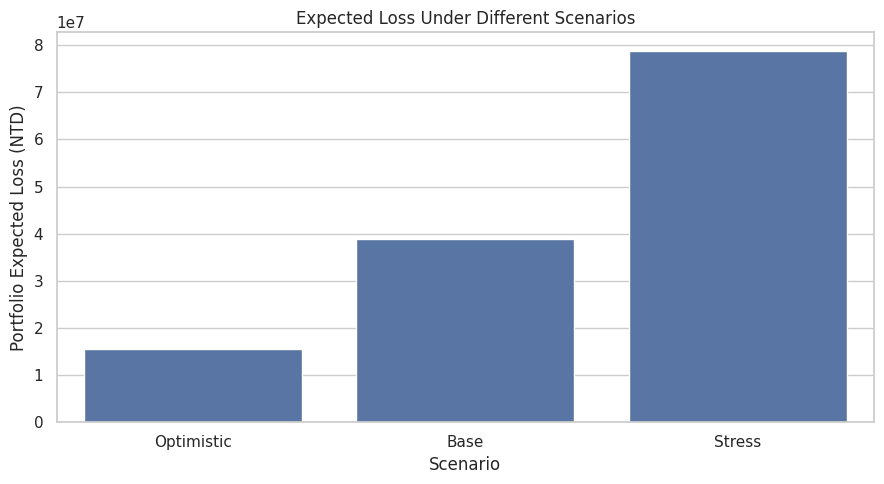

In [256]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=scenario_df,
    x="Scenario",
    y="Expected Loss"
)
plt.title("Expected Loss Under Different Scenarios")
plt.xlabel("Scenario")
plt.ylabel("Portfolio Expected Loss (NTD)")
plt.tight_layout()
plt.show()

### 9.5 Expected Loss Concentration

In [257]:
risk_sorted = risk_df.sort_values(
    "EXPECTED_LOSS",
    ascending=False
)

In [258]:
top_n = int(np.ceil(len(risk_sorted) * 0.10))
top_10_percent = risk_sorted.head(top_n)

In [259]:
top_10_el_share = (top_10_percent["EXPECTED_LOSS"].sum()/ risk_df["EXPECTED_LOSS"].sum() * 100)

In [260]:
print(f"Top 10% of clients account for "f"{top_10_el_share:.2f}% of total Expected Loss.")

Top 10% of clients account for 38.63% of total Expected Loss.


In [261]:
cumulative_el = (risk_sorted["EXPECTED_LOSS"].cumsum()/ risk_sorted["EXPECTED_LOSS"].sum() * 100)

In [262]:
cumulative_clients = (np.arange(1, len(risk_sorted) + 1)/ len(risk_sorted) * 100)

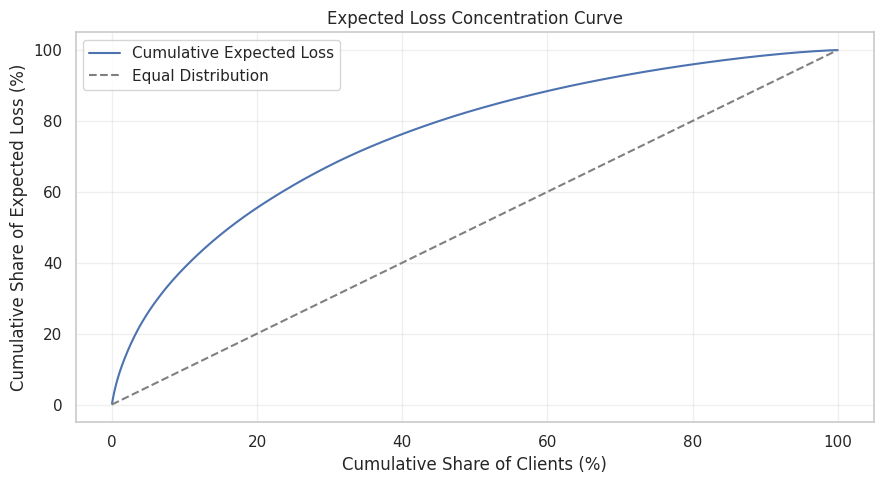

In [263]:
plt.figure(figsize=(9, 5))
plt.plot(
    cumulative_clients,
    cumulative_el,
    label="Cumulative Expected Loss"
)
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Equal Distribution"
)
plt.title("Expected Loss Concentration Curve")
plt.xlabel("Cumulative Share of Clients (%)")
plt.ylabel("Cumulative Share of Expected Loss (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The Expected Loss analysis estimated a total portfolio loss of approximately 38.96 million NTD under the base scenario, representing 7.73% of the assumed exposure at default. The Moderate Risk segment contributed the largest share of expected losses (33.76%), demonstrating that portfolio risk depends on both default probability and exposure size. Scenario analysis revealed substantial sensitivity to LGD and EAD assumptions, with estimated losses increasing from 15.58 million NTD under optimistic conditions to 78.79 million NTD under stress conditions. Furthermore, the top 10% of clients accounted for 38.63% of total expected losses, indicating notable risk concentration. Overall, these findings demonstrate how machine learning-based default probabilities can support portfolio risk assessment, although the financial estimates remain illustrative due to assumed LGD and EAD values.

## 10. Monte Carlo Credit Loss Simulation

### 10.1 Prepare Simulation Inputs

In [264]:
pd_values = risk_df["PD"].to_numpy()

In [265]:
loss_given_default = (
    risk_df["LGD"] * risk_df["EAD"]
).to_numpy()

In [266]:
assert np.isfinite(pd_values).all()
assert np.isfinite(loss_given_default).all()
assert ((pd_values >= 0) & (pd_values <= 1)).all()
assert (loss_given_default >= 0).all()

In [267]:
print("Number of clients:", len(pd_values))
print("Number of simulations:", 10000)

Number of clients: 6000
Number of simulations: 10000


### 10.2 Run Monte Carlo Simulation

In [268]:
n_simulations = 10000
batch_size = 500

In [269]:
rng = np.random.default_rng(42)

In [270]:
simulated_losses = np.empty(n_simulations)

In [271]:
for start in range(0, n_simulations, batch_size):
    end = min(start + batch_size, n_simulations)
    n_batch = end - start
    defaults = (
        rng.random((n_batch, len(pd_values)))
        < pd_values
    )
    simulated_losses[start:end] = (
        defaults @ loss_given_default
    )

In [272]:
print("Monte Carlo simulation completed!")
print("Number of simulations:", len(simulated_losses))

Monte Carlo simulation completed!
Number of simulations: 10000


### 10.3 Calculate Credit Risk Metrics

In [273]:
analytical_el = np.sum(
    pd_values * loss_given_default
)


In [274]:
simulated_el = np.mean(simulated_losses)

In [275]:
unexpected_loss = np.std(
    simulated_losses,
    ddof=1
)

In [276]:
var_95 = np.percentile(simulated_losses, 95)
var_99 = np.percentile(simulated_losses, 99)

In [277]:
es_95 = np.mean(
    simulated_losses[simulated_losses >= var_95]
)

In [278]:
es_99 = np.mean(
    simulated_losses[simulated_losses >= var_99]
)


In [279]:
simulation_summary = pd.DataFrame({
    "Metric": [
        "Analytical Expected Loss",
        "Simulated Expected Loss",
        "Unexpected Loss (Std. Dev.)",
        "Credit VaR 95%",
        "Credit VaR 99%",
        "Expected Shortfall 95%",
        "Expected Shortfall 99%"
    ],
    "Value (NTD)": [
        analytical_el,
        simulated_el,
        unexpected_loss,
        var_95,
        var_99,
        es_95,
        es_99
    ]
})

In [280]:
display(
    simulation_summary.style.format({
        "Value (NTD)": "{:,.2f}"
    })
)

,Metric,Value (NTD)
0,Analytical Expected Loss,"38,961,942.99"
1,Simulated Expected Loss,"38,968,140.40"
2,Unexpected Loss (Std. Dev.),"1,183,525.66"
3,Credit VaR 95%,"40,927,698.90"
4,Credit VaR 99%,"41,759,505.72"
5,Expected Shortfall 95%,"41,427,938.48"
6,Expected Shortfall 99%,"42,102,477.00"


### 10.4 Visualize Simulated Portfolio Losses

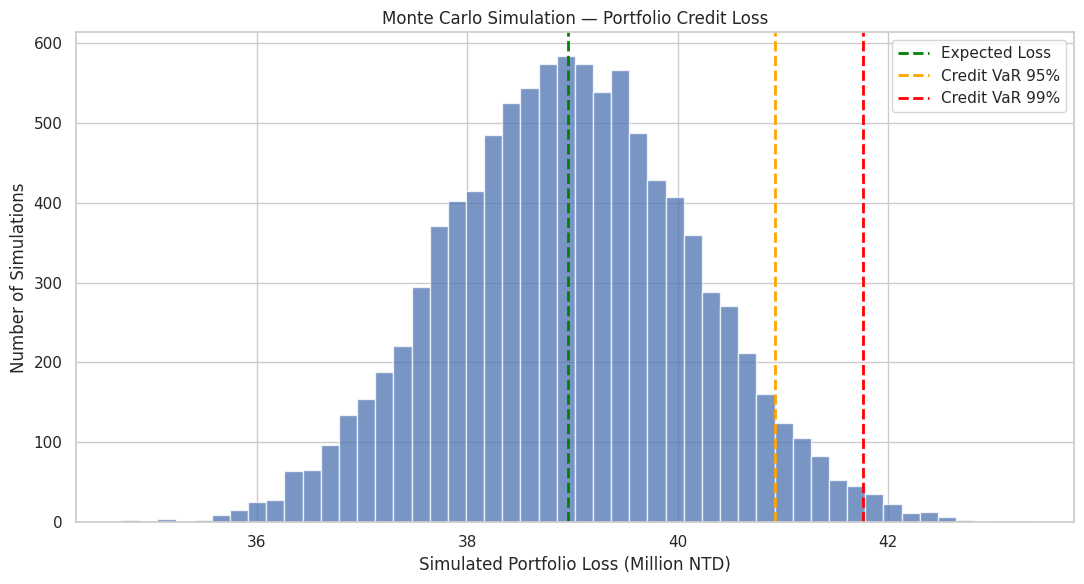

In [281]:
plt.figure(figsize=(11, 6))

plt.hist(
    simulated_losses / 1e6,
    bins=50,
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    analytical_el / 1e6,
    color="green",
    linestyle="--",
    linewidth=2,
    label="Expected Loss"
)

plt.axvline(
    var_95 / 1e6,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Credit VaR 95%"
)

plt.axvline(
    var_99 / 1e6,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Credit VaR 99%"
)

plt.title("Monte Carlo Simulation — Portfolio Credit Loss")
plt.xlabel("Simulated Portfolio Loss (Million NTD)")
plt.ylabel("Number of Simulations")
plt.legend()
plt.tight_layout()
plt.show()

### 10.5 Calculate Unexpected Loss Above Expected Loss

In [282]:
capital_buffer_99 = var_99 - analytical_el

In [283]:
print(f"Expected Loss: {analytical_el:,.2f} NTD")

Expected Loss: 38,961,942.99 NTD


In [284]:
print(f"Credit VaR 99%: {var_99:,.2f} NTD")

Credit VaR 99%: 41,759,505.72 NTD


In [285]:
print(f"VaR 99% minus Expected Loss: "f"{capital_buffer_99:,.2f} NTD")

VaR 99% minus Expected Loss: 2,797,562.73 NTD


### 10.6 Validate the Simulation

In [286]:
analytical_std = np.sqrt(
    np.sum(
        pd_values
        * (1 - pd_values)
        * loss_given_default**2
    )
)

In [287]:
validation_df = pd.DataFrame({
    "Metric": ["Expected Loss", "Loss Standard Deviation"],
    "Analytical": [analytical_el, analytical_std],
    "Simulated": [simulated_el, unexpected_loss]
})

In [288]:
validation_df["Difference (%)"] = (
    (validation_df["Simulated"] - validation_df["Analytical"])
    / validation_df["Analytical"] * 100
)

In [289]:
display(validation_df.round(2))

,Metric,Analytical,Simulated,Difference (%)
0,Expected Loss,38961942.99,38968140.40,0.02
1,Loss Standard Deviation,1187220.24,1183525.66,-0.31


The Monte Carlo simulation of 10,000 portfolio outcomes produced an average simulated loss of approximately 38.97 million NTD, closely matching the analytical Expected Loss of 38.96 million NTD. Unexpected Loss, measured as the standard deviation of simulated losses, was approximately 1.18 million NTD. The 95% and 99% Credit VaR estimates reached 40.93 million and 41.76 million NTD, respectively, while Expected Shortfall at the 99% level was approximately 42.10 million NTD. The minimal differences between analytical and simulated estimates confirmed the numerical consistency of the simulation. However, the results rely on independent default events and fixed LGD and EAD assumptions, potentially understating tail risk under correlated economic shocks.